<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QGAN_NetworkAnomaly_Hammami2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum GAN with successive data injection for network anomaly detection: Hammami, Cherkaoui and Wang (2025) step by step

This notebook re-implements, runs and checks the method of

> Wajdi Hammami, Soumaya Cherkaoui and Shengrui Wang, "Enhancing Network Anomaly Detection with Quantum GANs and Successive
> Data Injection for Multivariate Time Series", *2025 International Wireless Communications and Mobile Computing (IWCMC)*,
> IEEE, 2025. DOI 10.1109/IWCMC65282.2025.11059562 (arXiv:2505.11631)

The paper publishes no code. Everything below is written from its four-page description.

**What the notebook does.**
1. Streams the CSE-CIC-IDS2018 flow file of the DDoS day (20 February 2018, 4 GB) and condenses it to a *one-second multivariate
   time series* of two traffic features (mean forward inter-arrival time and mean forward packet length) with a per-second
   attack label. The series has exactly 32,401 entries, the number quoted in the paper.
2. Builds a **conditional quantum GAN**: a 4-qubit variational *generator* that predicts the next time step from a window of
   three, and a 6-qubit variational *discriminator* that scores (window, next step) pairs. Both use angle encoding
   (`RY(arccos x)`), *successive data injection* (SuDaI: the three time steps of the window are injected one per layer, between
   the variational layers) and, for the discriminator's extra "next-step" qubits, *data re-uploading*.
3. Trains the two circuits adversarially on benign traffic only, with the **parameter-shift rule**, using an exact NumPy
   state-vector simulator that is asserted equal to the PennyLane QNode that is drawn in the circuit-architecture section.
4. Turns the generator error and the discriminator score into the paper's combined anomaly score (Algorithm 1), sets the
   threshold at the 99.99th percentile of the benign training scores and reports accuracy / recall / precision / F1 / MSE for
   *discriminator only*, *generator only* and *combined* detection (the paper's Table I).
5. Compares with a classical conditional GAN with 51 + 55 parameters (and one with the same 80 parameters as the QGAN), runs the
   QGAN on a noisy density-matrix simulator with IBM "Vigo" error rates, repeats the paper's synthetic random-walk + sine
   experiment, and adds unsupervised and supervised classical reference detectors on the identical windows.
6. Ends with a side-by-side table of the paper's numbers and ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a pinned
PennyLane; if Colab asks to restart the session, do so and run all cells again. The 4 GB CSV is *streamed* (it is never stored; only
a ~15 MB per-second table is cached) which takes about 8-10 minutes on Colab the first time. `FAST_MODE = True` gives a class-demo
budget for the training; `FAST_MODE = False` uses the larger budgets documented in the configuration cell.

**What you get at the end.** The dataset plots, the circuits that are actually executed, trained models, a Table-I style result
table, a score-versus-time figure like the paper's Fig. 2, the noisy-simulator result, the synthetic-series experiment and a
verdict per claim.

## The paper in one page

**Problem.** Network anomaly detection on a *multivariate time series*: decide, second by second, whether traffic is benign or
under a DDoS attack, using a model trained on benign traffic only (unsupervised, GAN-based).

**Decision.** For a window of three consecutive seconds the generator predicts the fourth; the discriminator judges whether the
fourth second is consistent with the window. An anomaly score `S_t = w_G * MSE_t + w_D * (1 - D_t)` is thresholded.

**Method.**
- *Data*: CSE-CIC-IDS2018, DDoS day, flows aggregated per second, **two features** picked with a Granger-causality screening and
  domain knowledge: forward inter-arrival time and forward packet length. 32,401 entries; training:test = 0.5, training on the
  second half of the day (no attacks), test = the first half.
- *Scaling*: min-max to [-1, 1], then `arccos`, then an `RY` rotation (angle encoding).
- *Generator*: 4 qubits (2 per feature), three alternations of an input layer and a variational layer (SuDaI); variational layer =
  `RX`, `RZ` per qubit + a CNOT ring; output = `<Z>`; 30 parameters. *Discriminator*: 6 qubits (the 5th and 6th hold the real/predicted
  next point, re-uploaded in every layer); 50 parameters. Window size tau = 3, conditional GAN, MSE losses, parameter-shift
  training, learning rate 0.001, generator and discriminator trained equally.
- *Anomaly score*: Algorithm 1 (weights from the last generator / discriminator losses, threshold = 99.99th percentile of the benign
  training scores).
- *Evaluation*: Table I (QGAN discriminator-only / generator-only / combined, classical GAN, noisy QGAN on `Fake Vigo`), the synthetic
  series (random walk + modulated sine, Figs. 3-4: MSE 0.015 for the QGAN against 0.078 for the classical GAN) and Table II (DNN/CNN/RNN
  from another paper, quoted for the parameter counts).

**Paper claims we test.** Combined QGAN: accuracy 0.99, recall 0.97, precision 0.99, F1 0.98, MSE 0.0013. Discriminator-only: 0.83 / 0.35 / 0.98 / 0.51.
Generator-only: 0.26 / 1.00 / 0.26 / 0.41. Classical GAN (51 + 55 parameters): 0.96 / 0.86 / 0.99 / 0.92, MSE 0.0157. Noisy QGAN: 0.97 / 0.89 / 0.99 / 0.94, MSE 0.0042.
Total of 80 quantum parameters; QGAN MSE below the classical GAN's.

### What follows the paper and what had to be chosen

The paper is a four-page workshop paper. These are the places where it is silent and what this notebook does (each is marked `# CHOICE:` in the code).

| Item | Paper | This notebook |
|---|---|---|
| Dataset file | "CIC-CIDDS-2018 ... DDoS attack day (Thursday, February 20, 2018)" | The *Tuesday* 20-02-2018 file `Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv` (the CIC file is mis-spelt "Thuesday"; 20 Feb 2018 was a Tuesday). It is the only file of that date. Streamed from the official AWS bucket, Hugging Face mirror as fallback. |
| Time axis | 32,401 one-second entries | The CSV timestamps use a 12-hour clock without AM/PM (afternoon shows as 01:xx-05:xx). We map hours 1-7 to the afternoon/evening; 08:30:00-17:30:00 then contains **exactly 32,401** seconds, all non-empty. This identifies the paper's series. |
| Features | "Forward Inter-Arrival Time", "Forward Packet Length" | `Fwd IAT Mean` and `Fwd Pkt Len Mean` (mean over the flows that *start* in that second). Fixed *before* looking at any result. A Granger screening of ten related columns is shown, but not used for the choice (it uses labels of the whole day). |
| Attack label of a second | not stated | attack if at least one flow starting in that second is labelled attack |
| Train / test | train on the second half (no attacks), ratio 0.5 | first 16,200 s = test, last 16,201 s = train, **but** the second half contains a labelled attack burst (13:14-13:29, 454 s). Those seconds, and every window touching them, are removed from training. They are added as an extra "burst" test set. |
| Window / task | tau = 3, predict `x_{t+1}` | same |
| Scaling | min-max to [-1, 1] then `arccos` | min-max fitted on the benign training seconds, test values clipped to [-1, 1] before `arccos` |
| Qubit use of a feature | "first two qubits represent the first feature" | the same value `a_i` is written with `RY(arccos a_i)` on *both* qubits of the feature in layer i |
| Variational layer | `RX`, `RZ` + CNOT ring | exactly that, one `RX` and one `RZ` angle per qubit |
| Parameter counts | generator 30, discriminator 50 (80 total) | the layers described give 3 x 8 = 24 and 3 x 12 = 36 angles; one extra final variational layer (V4) gives **32 + 48 = 80** (same total, different split) |
| Generator output | `<Z>` | `<Z_0>` for feature a, `<Z_2>` for feature b; with `RY(arccos x)` an untouched qubit returns `x`, so the output lives in [-1, 1] like the data |
| Discriminator output | `<Z>` | `(1 + <Z_0>) / 2` in [0, 1]; the real/fake 'next step' sits on wires 4 (feature a) and 5 (feature b) |
| Initialisation | not stated | normal, standard deviation 0.1 (a near-identity circuit, so the generator starts as a persistence predictor) |
| Optimiser, learning rate | learning rate 0.001, optimiser not named | Adam; learning rate see the configuration cell |
| Epochs / batch | not stated | see the configuration cell (random mini-batches of windows) |
| Gradient of the generator | parameter-shift | parameter-shift for the generator circuit and for the discriminator's data angles, chained through `arccos` (derivative floored near +-1) |
| Loss | MSE, discriminator -> 1 for real, 0 for fake | exactly that (least-squares GAN) |
| Anomaly weights | from the last iteration's losses | mean of the last 25 training steps |
| Threshold | 99.99th percentile of benign training scores | same, on all benign training windows |
| Classical GAN | 51 and 55 parameters (MLPs) | tanh MLPs 6-4-3-2 (51 parameters) and 8-4-3-1 (55); plus 6-3-2 (29) and 8-5-1 (51) = 80 parameters in total |
| Noisy simulator | `Fake Vigo` | density-matrix simulation with depolarising noise whose rates are read from `FakeVigoV2` (single-qubit, CNOT and read-out errors); no routing/SWAPs (the ring does not fit Vigo's 5-qubit T-shape and the discriminator has 6 qubits) |
| Synthetic series | random walk + modulated sine, MSE 0.015 vs 0.078 | our own generator of such a series (length, periods not given), same step budget for both GANs |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "qiskit-ibm-runtime==0.50.0"
    print("PennyLane and qiskit-ibm-runtime (only used to read the Vigo error rates) installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo (a few minutes of training). False: the larger budgets listed below.
SEED      = 42             # CHOICE: the paper gives no seed
DATA_DIR  = "qc156_data"   # the per-second table (a few MB) is cached here; the 4 GB CSV itself is never stored
IBM_TOKEN = ""             # optional: real IBM hardware is NOT used in this notebook (the paper only used a noisy simulator)

# --- fixed by the paper
TAU          = 3           # window size
TRAIN_FRAC   = 0.5         # training : testing ratio of the 32,401-second series
THRESH_PCT   = 99.99       # anomaly threshold = 99.99th percentile of the benign training scores
FEATURES     = ["Fwd IAT Mean", "Fwd Pkt Len Mean"]   # CHOICE: the exact columns behind "forward inter-arrival time / packet length"
SERIES_START, SERIES_END = "2018-02-20 08:30:00", "2018-02-20 17:30:00"   # 32,401 s, identified from the paper's entry count

# --- budgets (the paper does not state epochs, batch size or optimiser)
if FAST_MODE:
    QGAN_STEPS, BATCH, SEEDS_Q = 150, 16, [SEED]     # one training step = one discriminator + one generator update
    CGAN_SEEDS               = [SEED + i for i in range(3)]
    SYN_STEPS                = 80
    N_NOISY                  = 192                         # windows used for the (slow) density-matrix evaluation, per split
else:
    QGAN_STEPS, BATCH, SEEDS_Q = 1000, 16, [SEED, SEED + 1, SEED + 2]
    CGAN_SEEDS               = [SEED + i for i in range(5)]
    SYN_STEPS                = 500
    N_NOISY                  = 768
LR_QGAN = 0.01          # Adam learning rate for the QGAN (paper: 0.001, see the discussion in section 6)
LR_CGAN = 0.001            # Adam learning rate for the classical GANs: the paper's value (in short validation-loss checks 0.003 and 0.01 were not better)
REG_STEPS, LR_REG = 1000, 0.05   # diagnostic only (section 6.2): generator trained by plain regression
INIT_STD = 0.1             # CHOICE: standard deviation of the initial rotation angles
VAL_FRAC = 0.10            # last 10 % (in time) of the training windows are held out to monitor the loss

In [3]:
import os, sys, json, time, math, warnings, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM, SVC
import pennylane as qml
warnings.filterwarnings("ignore")

# Hugging Face token: only needed if the AWS download fails and the HF mirror is used (that dataset is public, not gated).
# Locally it comes from the environment; in Colab from Settings > Secrets > HF_TOKEN. It is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| pennylane", qml.__version__, "| FAST_MODE =", FAST_MODE)

numpy 2.5.4 | pandas 3.0.6 | pennylane 0.45.1 | FAST_MODE = False


## 1. The data: CSE-CIC-IDS2018, 20 February 2018

The CSE-CIC-IDS2018 capture was produced by the Canadian Institute for Cybersecurity (CIC) and the Communications Security
Establishment (CSE) on AWS. For every day, CICFlowMeter turned the packet capture into one row per network *flow* with about 80
features and a label. We need one day only, the one with the DDoS attack (20 February 2018): **7.9 million flows, 4 GB**.

The function below streams the file in chunks of 500,000 rows, keeps only the timestamp, the label and the ten candidate columns,
and aggregates them to *one row per second* (the mean of each feature over the flows that start in that second, and the number of
benign / attack flows). Only that small table is written to `DATA_DIR`. The official source is the AWS Open Data bucket named in the
paper; a Hugging Face mirror of the same file is used if the bucket is unreachable.

In [4]:
CAND_COLS = ["Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min", "Fwd IAT Tot",
             "Fwd Pkt Len Mean", "Fwd Pkt Len Max", "Fwd Pkt Len Min", "Fwd Pkt Len Std", "TotLen Fwd Pkts"]
SRC_URLS = [
    # 1) the official CSE-CIC-IDS2018 AWS Open Data bucket (public, no token, 4.05 GB; the file name keeps the CIC typo "Thuesday")
    "https://cse-cic-ids2018.s3.ca-central-1.amazonaws.com/Processed%20Traffic%20Data%20for%20ML%20Algorithms/Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv",
    # 2) Hugging Face mirror of the same file (uses the reader's HF token if one is set; the dataset itself is not gated)
    "https://huggingface.co/datasets/c01dsnap/CIC-IDS2018/resolve/main/Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv",
]
CACHE_FILE = os.path.join(DATA_DIR, "qc156_second_series_v2.csv")

def _stream_aggregate(url):
    """Stream the 4 GB flow CSV in chunks and aggregate it to one row per second. Nothing larger than the
    per-second table (a few MB) is ever written to disk."""
    headers = {"Authorization": "Bearer " + HF_TOKEN} if (HF_TOKEN and "huggingface.co" in url) else {}
    resp = requests.get(url, headers=headers, stream=True, timeout=120)
    resp.raise_for_status()
    parts, label_counts, n_rows, t0 = [], {}, 0, time.time()
    for ch in pd.read_csv(resp.raw, usecols=["Timestamp", "Label"] + CAND_COLS, chunksize=500_000, low_memory=False):
        n_rows += len(ch)
        ch["ts"] = pd.to_datetime(ch["Timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
        ch = ch.dropna(subset=["ts"])
        ch["Label"] = ch["Label"].astype(str).str.strip()
        for k, v in ch["Label"].value_counts().items(): label_counts[k] = label_counts.get(k, 0) + int(v)
        agg = {}
        for c in CAND_COLS:
            ch[c] = pd.to_numeric(ch[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
            agg[c + "|sum"] = ch.groupby("ts")[c].sum()
            agg[c + "|cnt"] = ch.groupby("ts")[c].count()
        g = pd.DataFrame(agg)
        g["n_flows"] = ch.groupby("ts").size()
        g["n_attack"] = (ch["Label"] != "Benign").groupby(ch["ts"]).sum()
        g["n_benign"] = (ch["Label"] == "Benign").groupby(ch["ts"]).sum()
        parts.append(g)
        print(f"  streamed {n_rows:,} flows ({time.time() - t0:.0f} s)", flush=True)
    g = pd.concat(parts).groupby(level=0).sum()
    out = pd.DataFrame(index=g.index)
    for c in CAND_COLS: out[c] = g[c + "|sum"] / g[c + "|cnt"].replace(0, np.nan)
    out["n_flows"] = g["n_flows"]; out["n_attack"] = g["n_attack"]; out["n_benign"] = g["n_benign"]
    out.index.name = "ts_raw"
    return out, label_counts, n_rows

def load_second_series():
    """One row per second of 20 Feb 2018 (CSE-CIC-IDS2018): mean of each candidate feature over the flows that START in that second."""
    if os.path.exists(CACHE_FILE):
        out = pd.read_csv(CACHE_FILE, parse_dates=["ts_raw"], index_col="ts_raw")
        label_counts = json.load(open(CACHE_FILE + ".labels.json"))
        print("loaded cached per-second table", out.shape); return out, label_counts
    last_err = None
    for url in SRC_URLS:
        try:
            print("downloading/streaming:", url.split("/")[2]); out, label_counts, n_rows = _stream_aggregate(url); break
        except Exception as e:
            last_err = e; print("  failed:", repr(e)[:120])
    else:
        raise RuntimeError("could not download CSE-CIC-IDS2018 (Tuesday 20-02-2018); upload the CSV and adapt DATA_SOURCE") from last_err
    out.to_csv(CACHE_FILE); json.dump(label_counts, open(CACHE_FILE + ".labels.json", "w"))
    return out, label_counts

### 1.1 From flow timestamps to a 32,401-second time series

CICFlowMeter writes `dd/mm/yyyy hh:mm:ss` with a **12-hour clock and no AM/PM marker**, so 13:14 appears as `01:14`. The file starts around
08:30 and the afternoon traffic shows up under the hours 01-05 (the evening tail under 06-07). We therefore add 12 hours to the hours 1-7
(hour 12 is noon, hours 8-11 are the morning). Check: the published attack schedule for that day is LOIC-HTTP between about 10:12 and 11:12 and a
second burst at about 13:13, and the labelled flows in the data fall exactly there after this fix.

The paper says the series has **32,401 entries**. The span 08:30:00 to 17:30:00 inclusive is exactly 9 h + 1 s = 32,401 seconds and
every one of those seconds contains flows, so that is the series we use (a CHOICE inferred from the number).

In [5]:
raw, label_counts = load_second_series()
hr = raw.index.hour
fixed_index = raw.index + pd.to_timedelta(np.where((hr >= 1) & (hr <= 7), 12, 0), unit="h")   # CHOICE: 12-hour clock -> 24-hour clock
sec = raw.set_axis(fixed_index).sort_index()

series = sec.loc[SERIES_START:SERIES_END].copy()
print("entries between", SERIES_START, "and", SERIES_END, ":", len(series), "(paper: 32,401)")
full_grid = pd.date_range(SERIES_START, SERIES_END, freq="s")
print("seconds without any flow:", len(full_grid) - len(series))
series = series.reindex(full_grid)
series[FEATURES] = series[FEATURES].ffill()                     # only used if a second were empty (none are)
series["attack"] = (series["n_attack"].fillna(0) > 0).astype(int)   # CHOICE: attack second = at least one attack flow starts in it
series["t"] = np.arange(len(series))
T = len(series); T_HALF = int(TRAIN_FRAC * (T - 1))               # 16,200: seconds 0..16,199 = first half = test
print("series length", T, "| first half (test):", T_HALF, "s | second half (train):", T - T_HALF, "s")
print("attack seconds in first half :", int(series.attack[:T_HALF].sum()), "| in second half:", int(series.attack[T_HALF:].sum()))
seg = series.index[series.attack == 1].to_series()
gaps = (seg.diff().dt.total_seconds().fillna(0) > 60).cumsum()
for _, s in seg.groupby(gaps.values): print("  attack segment", s.min().time(), "->", s.max().time(), f"({len(s)} attack seconds)")

loaded cached per-second table (38478, 13)
entries between 2018-02-20 08:30:00 and 2018-02-20 17:30:00 : 32401 (paper: 32,401)
seconds without any flow: 0
series length 32401 | first half (test): 16200 s | second half (train): 16201 s
attack seconds in first half : 3775 | in second half: 454
  attack segment 10:13:54 -> 11:16:48 (3775 attack seconds)
  attack segment 13:14:17 -> 13:15:16 (59 attack seconds)
  attack segment 13:16:17 -> 13:29:15 (395 attack seconds)


## 2. Preprocessing: scaling, windows, the benign training set

1. **Scaling.** Min-max to [-1, 1] per feature, **fitted on the benign seconds of the training half only**. Test values outside the
   training range (attacks!) are clipped to [-1, 1] before `arccos` (the angle is undefined outside).
2. **Windows.** For every target second `j` the window is the three previous seconds `x_{j-3}, x_{j-2}, x_{j-1}` (each a pair of
   scaled features) and the label is the label of second `j`.
3. **Training set** = windows entirely inside the second half whose four seconds are all benign. The paper says the second half has no attacks;
   in the data it contains the 13:14-13:29 burst (454 attack seconds), so those windows are removed (a deviation, listed in the table above).
4. **Test set A** = windows entirely inside the first half (the paper's test half). **Test set B** = A plus the windows of the second half that
   touch the held-out burst, which brings in the second attack burst (the paper's reported precision of 0.26 for "flag everything" implies
   about 26 % attacks in its test set, which is what A + burst gives).
5. The last 10 % (in time) of the training windows are held out as a validation set to monitor the losses; the networks are fitted on the rest.

In [6]:
benign_train_sec = (series.t >= T_HALF) & (series.attack == 0)
lo = series.loc[benign_train_sec, FEATURES].min().values; hi = series.loc[benign_train_sec, FEATURES].max().values   # fitted on train only
Xraw = series[FEATURES].values
Xs = np.clip(2 * (Xraw - lo) / (hi - lo) - 1, -1, 1)                  # (T, 2) in [-1, 1]
atk = series.attack.values

J = np.arange(TAU, T)                                                  # target second of every window
Wall = np.stack([Xs[J - 3], Xs[J - 2], Xs[J - 1]], axis=1)             # (n, 3, 2)
Yall = Xs[J]                                                            # (n, 2)
Lall = atk[J]
touch = np.max([atk[J - 3], atk[J - 2], atk[J - 1], atk[J]], axis=0)  # any attack second inside the 4 seconds
first = J < T_HALF                                                      # whole window inside the first half
second = (J - 3) >= T_HALF
m_train, m_testA, m_burst = second & (touch == 0), first, second & (touch == 1)
m_testB = m_testA | m_burst

W_tr_all, Y_tr_all, J_tr_all = Wall[m_train], Yall[m_train], J[m_train]
n_val = int(VAL_FRAC * len(W_tr_all)); n_fit = len(W_tr_all) - n_val
W_fit, Y_fit = W_tr_all[:n_fit], Y_tr_all[:n_fit]
W_val, Y_val = W_tr_all[n_fit:], Y_tr_all[n_fit:]
W_A, Y_A, L_A, J_A = Wall[m_testA], Yall[m_testA], Lall[m_testA], J[m_testA]
W_B, Y_B, L_B, J_B = Wall[m_testB], Yall[m_testB], Lall[m_testB], J[m_testB]
print(f"scaling range (train, benign): {dict(zip(FEATURES, zip(lo.round(1), hi.round(1))))}")
print(f"train windows {len(W_tr_all)} (fit {n_fit}, validation {n_val}) | test A {len(W_A)} windows, {L_A.mean():.3f} attacks "
      f"| test B {len(W_B)} windows, {L_B.mean():.3f} attacks")
print(f"reference MSEs on the validation windows: predict-the-training-mean {((Y_fit.mean(0) - Y_val) ** 2).mean():.4f} | persistence (predict x_t) {((W_val[:, -1, :] - Y_val) ** 2).mean():.4f} | paper: 0.0013 (QGAN), 0.0157 (classical GAN)")
print("share of test-A values clipped by the scaler:", np.round((np.abs(2 * (Xraw[:T_HALF] - lo) / (hi - lo) - 1) > 1).mean(0), 4))

scaling range (train, benign): {'Fwd IAT Mean': (np.float64(208206.6), np.float64(13448320.4)), 'Fwd Pkt Len Mean': (np.float64(25.6), np.float64(89.9))}
train windows 15687 (fit 14119, validation 1568) | test A 16197 windows, 0.233 attacks | test B 16708 windows, 0.253 attacks
reference MSEs on the validation windows: predict-the-training-mean 0.1245 | persistence (predict x_t) 0.0826 | paper: 0.0013 (QGAN), 0.0157 (classical GAN)
share of test-A values clipped by the scaler: [0.0034 0.0435]


## Dataset Exploration and Visualisation

Everything on this page is computed from the real CSE-CIC-IDS2018 flows (no synthetic or invented data). We print the shape, the
features and the original labels, plot the class distributions and then look at the observations themselves: the two selected
features over time, and a two-dimensional scatter of the real windows coloured by their ground-truth label (PCA coordinates fitted
on the training split, then the same coordinates scaled to [0, pi] and the actual encoding angles).

In [7]:
print("per-second table of the DDoS day:", sec.shape, "  (series used:", series.shape, ")")
print("candidate feature columns :", CAND_COLS)
print("model features            :", FEATURES)
print("other columns             :", [c for c in series.columns if c not in CAND_COLS])
print("\noriginal flow-level labels in the 4.05 GB file (counts of flows):")
for k, v in sorted(label_counts.items(), key=lambda kv: -kv[1]): print(f"   {k:28s} {v:>10,d}")
print("\nper-second labels used here (attack second = at least one attack flow):")
print(series.groupby(["attack"]).size().rename({0: "benign second", 1: "attack second"}).to_string())
print("\nsplit halves (seconds):")
print(pd.crosstab(pd.Series(np.where(series.t < T_HALF, "first half (test)", "second half (train)"), index=series.index, name="half"),
                  series.attack.map({0: "benign", 1: "attack"}).rename("label")).to_string())
display(series[FEATURES + ["n_flows", "n_attack", "attack"]].describe().T.round(2))

per-second table of the DDoS day: (38478, 13)   (series used: (32401, 15) )
candidate feature columns : ['Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Fwd IAT Tot', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Std', 'TotLen Fwd Pkts']
model features            : ['Fwd IAT Mean', 'Fwd Pkt Len Mean']
other columns             : ['n_flows', 'n_attack', 'n_benign', 'attack', 't']

original flow-level labels in the 4.05 GB file (counts of flows):
   Benign                        7,372,557
   DDoS attacks-LOIC-HTTP          576,191

per-second labels used here (attack second = at least one attack flow):
attack
benign second    28172
attack second     4229

split halves (seconds):


label                attack  benign
half                               
first half (test)      3775   12425
second half (train)     454   15747


,count,mean,std,min,25%,50%,75%,max
Fwd IAT Mean,32401.0,3509310.96,1736251.07,208206.64,2315903.14,3124798.85,4297868.72,24816381.19
Fwd Pkt Len Mean,32401.0,47.12,9.60,10.55,41.96,47.21,52.68,111.95
n_flows,32401.0,243.15,96.16,55.00,173.00,225.00,294.00,767.00
n_attack,32401.0,17.78,51.18,0.00,0.00,0.00,0.00,296.00
attack,32401.0,0.13,0.34,0.00,0.00,0.00,0.00,1.00


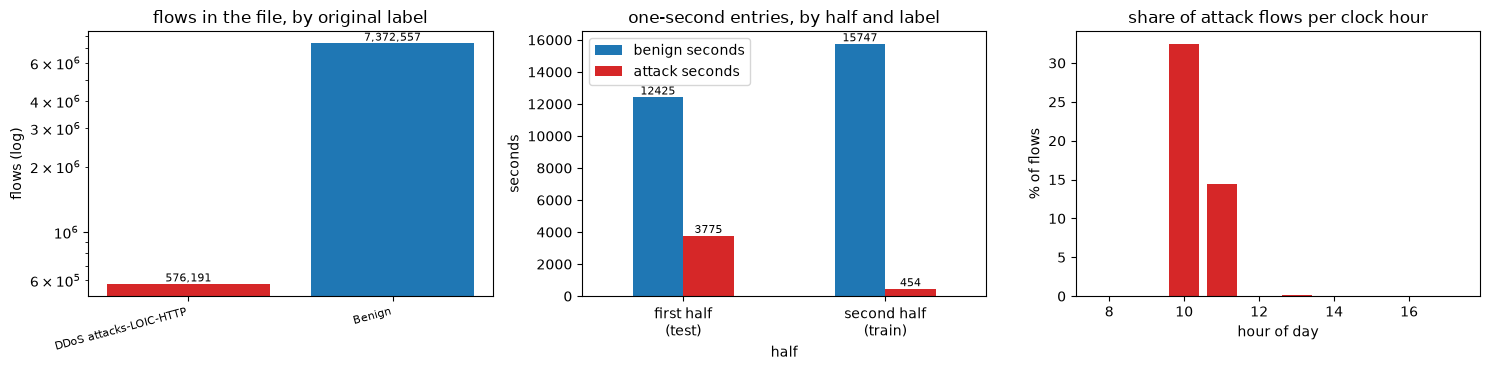

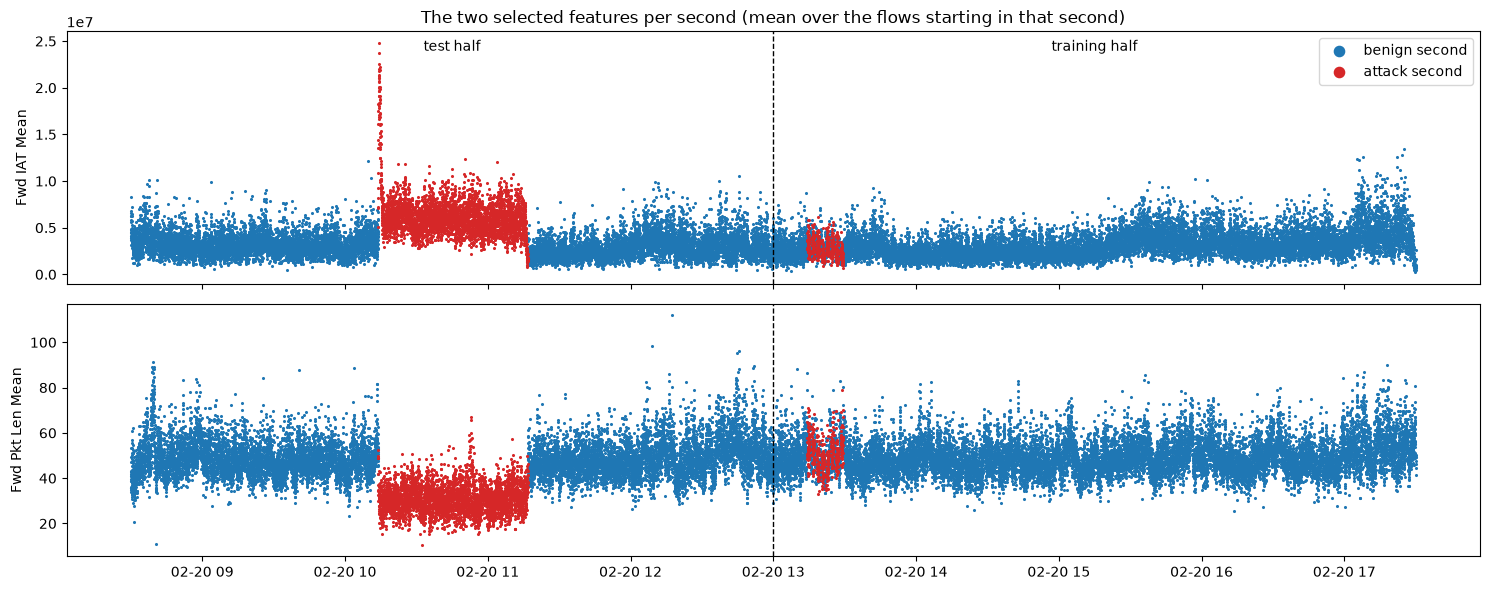

In [8]:
# class distribution: flow level (as labelled in the file) and second level (as used by the model)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = list(label_counts.keys()); vals = [label_counts[k] for k in names]
cols = ["tab:blue" if k == "Benign" else "tab:red" for k in names]
ax[0].bar(range(len(names)), vals, color=cols); ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=15, ha="right", fontsize=8)
ax[0].set_yscale("log"); ax[0].set_title("flows in the file, by original label"); ax[0].set_ylabel("flows (log)")
for i, v in enumerate(vals): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
cnt = series.assign(half=np.where(series.t < T_HALF, "first half\n(test)", "second half\n(train)")).groupby(["half", "attack"]).size().unstack(fill_value=0)
cnt.columns = ["benign seconds", "attack seconds"]
cnt.plot.bar(ax=ax[1], color=["tab:blue", "tab:red"], rot=0); ax[1].set_title("one-second entries, by half and label"); ax[1].set_ylabel("seconds")
for p in ax[1].patches: ax[1].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
share = series.groupby(series.index.hour).apply(lambda d: d.n_attack.sum() / max(d.n_flows.sum(), 1))
ax[2].bar(share.index, share.values * 100, color="tab:red"); ax[2].set_title("share of attack flows per clock hour"); ax[2].set_xlabel("hour of day"); ax[2].set_ylabel("% of flows")
plt.tight_layout(); plt.show()

# the two model features over the day, every point is a real second coloured by its ground-truth label
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
for a, f in zip(ax, FEATURES):
    b = series.attack == 0
    a.scatter(series.index[b], series.loc[b, f], s=1.5, c="tab:blue", label="benign second")
    a.scatter(series.index[~b], series.loc[~b, f], s=1.5, c="tab:red", label="attack second")
    a.axvline(series.index[T_HALF], color="k", ls="--", lw=1); a.set_ylabel(f)
ax[0].legend(markerscale=6, loc="upper right"); ax[0].text(series.index[T_HALF // 2], ax[0].get_ylim()[1] * 0.92, "test half", ha="center")
ax[0].text(series.index[T_HALF + (T - T_HALF) // 2], ax[0].get_ylim()[1] * 0.92, "training half", ha="center")
ax[0].set_title("The two selected features per second (mean over the flows starting in that second)"); plt.tight_layout(); plt.show()

### Feature screening with Granger causality (display only)

The paper picked its two features with a Granger-causality test between network metrics and the label on the DDoS day. We repeat
that kind of test on ten related columns (does the past of the feature help to predict the attack label, lag 3, F-test), to
see what the paper saw. **We do not use it to choose the features**, because it uses the labels of the whole day, including the
period that is later our test set; the two features were fixed in the configuration cell beforehand.

In [9]:
def granger_F(y, x, p=3):
    """F-test: do p lags of x improve an AR(p) model of y?  Returns (F, p-value)."""
    n = len(y); Y = y[p:]
    ly = np.column_stack([y[p - k:n - k] for k in range(1, p + 1)]); lx = np.column_stack([x[p - k:n - k] for k in range(1, p + 1)])
    X0 = np.column_stack([np.ones(n - p), ly]); X1 = np.column_stack([X0, lx])
    r0 = Y - X0 @ np.linalg.lstsq(X0, Y, rcond=None)[0]; r1 = Y - X1 @ np.linalg.lstsq(X1, Y, rcond=None)[0]
    dfn, dfd = p, n - p - X1.shape[1]
    F = ((r0 @ r0 - r1 @ r1) / dfn) / (r1 @ r1 / dfd)
    return F, stats.f.sf(F, dfn, dfd)

yv = series.attack.values.astype(float)
rows = []
for c in CAND_COLS:
    xv = series[c].ffill().values; xv = (xv - xv.mean()) / xv.std()
    F, pv = granger_F(yv, xv)
    rows.append((c, round(F, 1), pv, "<-- used" if c in FEATURES else ""))
gr = pd.DataFrame(rows, columns=["candidate column", "Granger F (lag 3)", "p-value", "model feature"]).sort_values("Granger F (lag 3)", ascending=False)
display(gr.style.format({"p-value": "{:.2e}"}))

,candidate column,Granger F (lag 3),p-value,model feature
9,TotLen Fwd Pkts,86.000000,2.03e-55,
3,Fwd IAT Min,9.700000,2.21e-06,
5,Fwd Pkt Len Mean,8.300000,1.57e-05,<-- used
0,Fwd IAT Mean,8.200000,1.89e-05,<-- used
6,Fwd Pkt Len Max,4.700000,2.64e-03,
8,Fwd Pkt Len Std,4.500000,3.55e-03,
2,Fwd IAT Max,3.700000,1.14e-02,
1,Fwd IAT Std,2.600000,4.95e-02,
7,Fwd Pkt Len Min,0.600000,6.11e-01,
4,Fwd IAT Tot,0.000000,9.87e-01,


### Scatter of the real windows, coloured by ground truth

Each window is a point in a 6-dimensional space (three seconds x two features). We project it to two dimensions with a PCA fitted on the
training windows, then show the same coordinates scaled to [0, pi] (as they would enter an angle-encoded circuit) and, last, the two angles
that the quantum circuits really use for the most recent second, `arccos(a)` and `arccos(b)`. Colours are the ground-truth labels: grey =
benign training window, blue = benign test window, red = attack window (label of the target second).

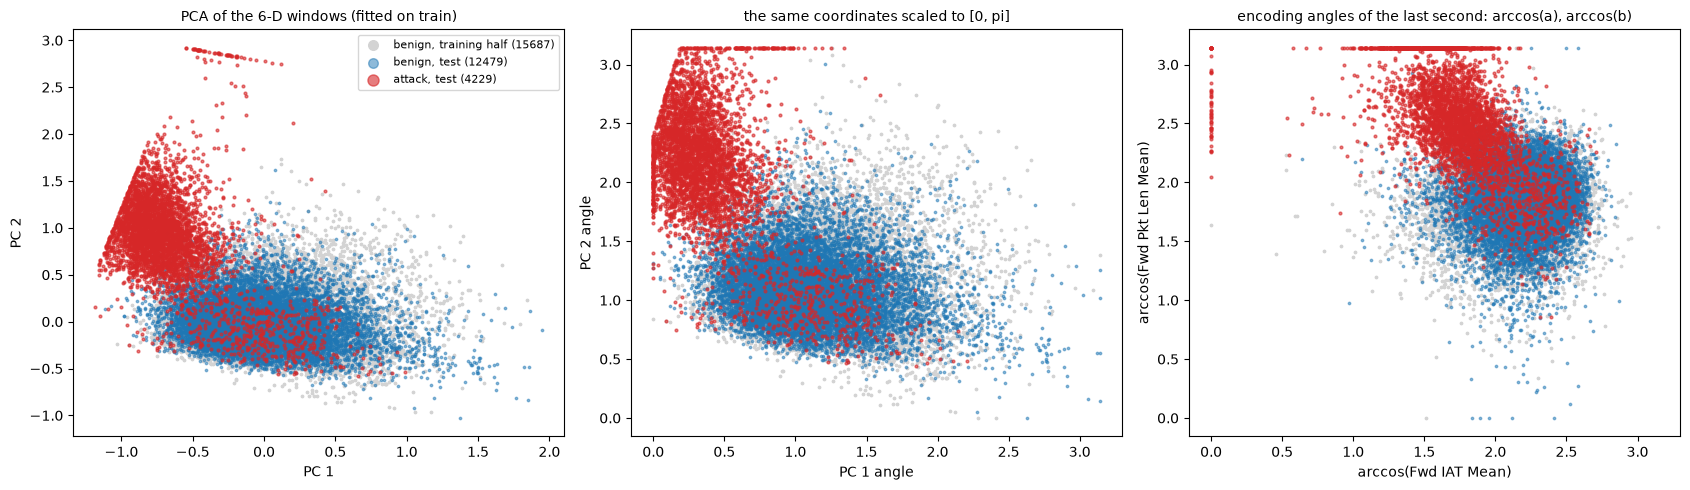

explained variance of the two PCA axes: [0.41  0.269]


In [10]:
flat = lambda W: W.reshape(len(W), -1)
pca = PCA(n_components=2, random_state=SEED).fit(flat(W_tr_all))
P_tr, P_te = pca.transform(flat(W_tr_all)), pca.transform(flat(W_B))
sc = MinMaxScaler((0, np.pi)).fit(P_tr)
S_tr, S_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)
ang_tr, ang_te = np.arccos(W_tr_all[:, -1, :]), np.arccos(W_B[:, -1, :])
isB_burst = np.isin(J_B, J[m_burst])
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, (A_tr, A_te, ttl, xl, yl) in zip(ax, [(P_tr, P_te, "PCA of the 6-D windows (fitted on train)", "PC 1", "PC 2"),
                                              (S_tr, S_te, "the same coordinates scaled to [0, pi]", "PC 1 angle", "PC 2 angle"),
                                              (ang_tr, ang_te, "encoding angles of the last second: arccos(a), arccos(b)", "arccos(Fwd IAT Mean)", "arccos(Fwd Pkt Len Mean)")]):
    a.scatter(A_tr[:, 0], A_tr[:, 1], s=3, c="lightgrey", label=f"benign, training half ({len(A_tr)})")
    bt = (L_B == 0); at = (L_B == 1)
    a.scatter(A_te[bt, 0], A_te[bt, 1], s=3, c="tab:blue", alpha=.5, label=f"benign, test ({bt.sum()})")
    a.scatter(A_te[at, 0], A_te[at, 1], s=4, c="tab:red", alpha=.6, label=f"attack, test ({at.sum()})")
    a.set_title(ttl, fontsize=10); a.set_xlabel(xl); a.set_ylabel(yl)
ax[0].legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()
print("explained variance of the two PCA axes:", pca.explained_variance_ratio_.round(3))

## 3. The quantum models: how they are simulated

**Circuits** (paper, Section II.B and Fig. 1). For a window `(x_{j-3}, x_{j-2}, x_{j-1})` with `x = (a, b)`:

*Generator* (4 qubits, wires 0-1 carry feature a, wires 2-3 feature b). For `i = 1, 2, 3`: input layer `RY(arccos a_i)` on wires 0 and 1 and
`RY(arccos b_i)` on wires 2 and 3 (**successive data injection**: one time step per layer), then a variational layer (`RX(t)` and `RZ(t')` on every
qubit followed by a ring of CNOTs 0-1, 1-2, 2-3, 3-0). A final variational layer V4 closes the circuit. Outputs `<Z_0>` (predicted a) and `<Z_2>` (predicted b).

*Discriminator* (6 qubits). The same four wires with the same window, plus wire 4 carrying the real/predicted next value of feature a and wire 5 the
next value of feature b, written again in every input layer (**data re-uploading**). Output `<Z_0>`, mapped to a score in [0, 1].

**Simulator.** Training uses the parameter-shift rule, which needs two extra circuit evaluations (angle +pi/2 and -pi/2) for each of the `P` trainable angles.
PennyLane executes one circuit at a time, which would take hours here, so training uses a small exact NumPy state-vector simulator. It exploits that a shifted circuit differs
from the base circuit by **one extra rotation**: shifting an `RX` angle by +-pi/2 equals inserting `RX(+-pi/2)` in front of the variational layer, shifting an `RZ` angle equals
inserting `RZ(+-pi/2)` behind its rotations. All `2P` shifted circuits therefore share the unshifted prefix and the unshifted layer matrices and are simulated together as
extra "columns" of one batched matrix product. The circuit-architecture section below asserts that this simulator reproduces the PennyLane QNode (the object that is drawn) to
machine precision, for random parameters and inputs, for both circuits, and that its parameter-shift Jacobian equals PennyLane's own parameter-shift Jacobian.

In [11]:
class Arch:
    """Circuit layout shared by the NumPy simulator and the PennyLane QNode."""
    def __init__(self, n_qubits, n_layers, data_wires, out_wires, n_final=1):
        self.n = n_qubits; self.L = n_layers; self.n_final = n_final   # n_final = extra variational layers V4
        self.data_wires = data_wires            # list of (wire list) for each of the encoded variable
        self.out_wires = out_wires
        self.n_var = (n_layers + n_final) * n_qubits * 2

_PERM = {}

def _cx_ring_perm(n):
    idx = np.arange(2 ** n)
    # build composite permutation by applying CX(c,t) sequentially to index arrays
    comp = np.arange(2 ** n)
    for c in range(n):
        t = (c + 1) % n
        step = idx ^ (((idx >> (n - 1 - c)) & 1) << (n - 1 - t))
        comp = comp[step]          # state_after = state_before[step]; compose: s1=s0[comp], s2=s1[step]=s0[comp[step]]
    return comp

def _mat_ry(phi):
    c, s = np.cos(phi / 2), np.sin(phi / 2)
    m = np.empty(phi.shape + (2, 2), complex)
    m[..., 0, 0] = c; m[..., 0, 1] = -s; m[..., 1, 0] = s; m[..., 1, 1] = c
    return m

def _mat_rzrx(t1, t2):
    """RZ(t2) @ RX(t1) as one 2x2 matrix (RX applied first), closed form."""
    c, s = np.cos(t1 / 2), np.sin(t1 / 2)
    e = np.exp(-1j * t2 / 2)
    m = np.empty(t1.shape + (2, 2), complex)
    m[..., 0, 0] = e * c; m[..., 0, 1] = -1j * e * s
    m[..., 1, 0] = -1j * np.conj(e) * s; m[..., 1, 1] = np.conj(e) * c
    return m

def _kron_stack(mats):
    """mats: list of arrays (K,2,2); returns (K, 2^n, 2^n) = mats[0] (x) mats[1] (x) ... (wire 0 = most significant)."""
    U = mats[0]
    for m in mats[1:]:
        K = U.shape[0]; d = U.shape[1]
        U = (U[:, :, None, :, None] * m[:, None, :, None, :]).reshape(K, d * 2, d * 2)
    return U

def _sign_table(arch):
    dim = 2 ** arch.n
    return np.stack([1 - 2 * ((np.arange(dim) >> (arch.n - 1 - w)) & 1) for w in arch.out_wires], axis=1)   # (dim, n_out): +-1 eigenvalues of Z_w

def _apply_ry(psi, q, n, angle):
    """RY(angle_b) on qubit q of every sample b. psi: (B, dim, V); angle: (B,)."""
    B, dim, V = psi.shape
    s = psi.reshape(B, 2 ** q, 2, (2 ** (n - q - 1)) * V)
    c = np.cos(angle / 2)[:, None, None]; sn = np.sin(angle / 2)[:, None, None]
    out = np.empty_like(s)
    out[:, :, 0] = c * s[:, :, 0] - sn * s[:, :, 1]
    out[:, :, 1] = sn * s[:, :, 0] + c * s[:, :, 1]
    return out.reshape(B, dim, V)

def _apply_rx_const(psi, q, n, delta):
    """RX(delta) (same angle for all samples) on qubit q. psi: (B, dim, V)."""
    B, dim, V = psi.shape
    s = psi.reshape(B, 2 ** q, 2, (2 ** (n - q - 1)) * V)
    c, sn = np.cos(delta / 2), -1j * np.sin(delta / 2)
    out = np.empty_like(s)
    out[:, :, 0] = c * s[:, :, 0] + sn * s[:, :, 1]
    out[:, :, 1] = sn * s[:, :, 0] + c * s[:, :, 1]
    return out.reshape(B, dim, V)

def forward_ps(arch, theta, phi, jac=True):
    """Exact state-vector simulation of the circuit for a batch of B inputs (phi: (B, n_vars, L) encoding angles).
    Returns <Z_w> of shape (B, n_out) and, if jac, the parameter-shift Jacobian (P, B, n_out):  dE/dtheta_p = [E(theta_p + pi/2) - E(theta_p - pi/2)] / 2.
    The 2P shifted circuits differ from the base circuit by ONE extra rotation, RX(+-pi/2) before a variational layer (shift of an RX angle) or RZ(+-pi/2)
    after its rotations (shift of an RZ angle); all circuits share the unshifted prefix and the unshifted layer unitaries, so they are simulated together."""
    n, dim, B = arch.n, 2 ** arch.n, phi.shape[0]
    th = theta.reshape(arch.L + arch.n_final, n, 2)
    if n not in _PERM: _PERM[n] = _cx_ring_perm(n)
    perm = _PERM[n]
    zq = [1 - 2 * ((np.arange(dim) >> (n - 1 - q)) & 1) for q in range(n)]              # +1/-1 eigenvalue of Z_q on each basis state
    wire_var = {w: v for v, ws in enumerate(arch.data_wires) for w in ws}
    psi = np.zeros((B, dim, 1), complex); psi[:, 0, 0] = 1.0
    meta = [(-1, 0)]                                                                     # (parameter index, sign) of every circuit; (-1,0) = base circuit
    for l in range(arch.L + arch.n_final):
        if l < arch.L:                                                                   # input layer: RY(arccos x) on the data wires
            for w in range(n): psi = _apply_ry(psi, w, n, phi[:, wire_var[w], l])
        M = _kron_stack([_mat_rzrx(th[l, q, 0:1], th[l, q, 1:2]) for q in range(n)])[0]  # (dim, dim): RZ.RX on every qubit
        if jac:
            base = psi[:, :, :1]
            extra = []
            for q in range(n):
                for sgn in (+1, -1):
                    extra.append(_apply_rx_const(base, q, n, sgn * np.pi / 2)); meta.append(((l * n + q) * 2 + 0, sgn))
            psi = np.concatenate([psi] + extra, axis=2)
        psi = np.matmul(M, psi)
        if jac:
            base = psi[:, :, :1]
            extra = []
            for q in range(n):
                for sgn in (+1, -1):
                    extra.append(base * np.exp(-1j * sgn * np.pi / 4 * zq[q])[None, :, None]); meta.append(((l * n + q) * 2 + 1, sgn))
            psi = np.concatenate([psi] + extra, axis=2)
        psi = psi[:, perm, :]                                                            # CNOT ring (a permutation of the basis states)
    out = np.einsum('bdv,do->bvo', np.abs(psi) ** 2, _sign_table(arch))                  # (B, V, n_out)
    if not jac: return out[:, 0, :], None
    P = arch.n_var; J = np.zeros((P, B, out.shape[2]))
    for v, (p, sgn) in enumerate(meta):
        if p >= 0: J[p] += 0.5 * sgn * out[:, v, :]
    return out[:, 0, :], J

def expect(arch, theta, phi, chunk=1024):
    return np.concatenate([forward_ps(arch, theta, phi[i:i + chunk], jac=False)[0] for i in range(0, len(phi), chunk)])

# helpers used only by the noisy density-matrix simulator (section 7)
def enc_unitaries(arch, phi):
    """phi (B, n_vars, L) -> list over layers of (B, 2^n, 2^n) RY-product matrices."""
    n = arch.n
    wire_var = {w: v for v, ws in enumerate(arch.data_wires) for w in ws}
    return [_kron_stack([_mat_ry(phi[:, wire_var[w], l]) for w in range(n)]) for l in range(arch.L)]

### 3.1 Training the QGAN: parameter-shift gradients and the adversarial step

One training step on a mini-batch of windows `(W, y)`:

1. `y_fake = G(W)`. **Discriminator update**: real pairs `(W, y)` should score 1, fake pairs `(W, y_fake)` 0; the loss is the mean squared error and the gradient of the
   `6`-qubit circuit with respect to its `48` angles comes from the parameter-shift rule `dE/dtheta = [E(theta + pi/2) - E(theta - pi/2)] / 2` (valid because every trainable angle is a
   Pauli rotation angle used once).
2. **Generator update**: the discriminator should score `(W, G(W))` as 1. The gradient flows through the discriminator's data angle `arccos(y_fake)` (again a rotation angle, so
   parameter-shift applies to each of its three re-uploaded copies) and through the generator's own parameter-shift Jacobian. The derivative of `arccos` is floored near +-1.
3. Adam with the learning rate of the configuration cell.

A finite-difference check of the whole generator gradient is in the next-but-one cell.

In [12]:
G_ARCH = Arch(4, 3, [[0, 1], [2, 3]], [0, 2])           # generator: wires 0,1 <- feature a, wires 2,3 <- feature b, outputs <Z0>, <Z2>
D_ARCH = Arch(6, 3, [[0, 1], [2, 3], [4], [5]], [0])    # discriminator: + wire 4 <- next a, wire 5 <- next b (re-uploaded), output <Z0>

def ps_jacobian(arch, theta, phi):
    """Base expectation (B,n_out) and parameter-shift Jacobian (P,B,n_out): dE/dtheta_p = [E(+pi/2) - E(-pi/2)] / 2."""
    return forward_ps(arch, theta, phi, jac=True)

def windows_to_phi_G(Wn):
    """Wn: (B, 3, 2) values in [-1,1] -> encoding angles (B, 2, 3) = arccos, per variable and layer."""
    return np.arccos(np.clip(Wn, -1, 1)).transpose(0, 2, 1)

def phi_D(Wn, y):
    """Discriminator angles (B, 4, 3): window a (3 steps), window b, next a (re-uploaded x3), next b (re-uploaded x3)."""
    pw = windows_to_phi_G(Wn)
    py = np.arccos(np.clip(y, -1, 1))
    return np.concatenate([pw, np.repeat(py[:, 0, None, None], 3, 2), np.repeat(py[:, 1, None, None], 3, 2)], axis=1)

def gen_predict(theta_g, Wn):
    return expect(G_ARCH, theta_g, windows_to_phi_G(Wn))                            # (B,2) in [-1,1]

def disc_score(theta_d, Wn, y):
    return 0.5 * (1 + expect(D_ARCH, theta_d, phi_D(Wn, y))[:, 0])                  # (B,) in [0,1]

class Adam:
    def __init__(self, n, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(n); self.v = np.zeros(n); self.t = 0; self.lr = lr; self.b1 = b1; self.b2 = b2; self.eps = eps
    def step(self, theta, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g * g
        mh = self.m / (1 - self.b1 ** self.t); vh = self.v / (1 - self.b2 ** self.t)
        return theta - self.lr * mh / (np.sqrt(vh) + self.eps)

def qgan_step(tg, td, Wn, y, opt_g, opt_d, dclip=1e-2):
    """One conditional-QGAN iteration: a discriminator update then a generator update, both with the parameter-shift rule."""
    B = len(Wn)
    # ---- discriminator: real -> 1, fake -> 0 (MSE)
    yf = gen_predict(tg, Wn)
    Wb = np.concatenate([Wn, Wn]); yb = np.concatenate([y, yf]); tgt = np.concatenate([np.ones(B), np.zeros(B)])
    z0, jz = ps_jacobian(D_ARCH, td, phi_D(Wb, yb))
    s = 0.5 * (1 + z0[:, 0]); ds = 0.5 * jz[:, :, 0]                                # (2B,), (P,2B)
    loss_d = np.mean((s - tgt) ** 2)                                                 # average of real-MSE and fake-MSE
    grad_d = (2 * (s - tgt)[None] * ds).mean(1)
    td = opt_d.step(td, grad_d)
    # ---- generator: make D(window, G(window)) -> 1
    grad_g, loss_g = generator_gradient(tg, td, Wn, dclip)
    tg = opt_g.step(tg, grad_g)
    return tg, td, loss_g, loss_d

def generator_gradient(tg, td, Wn, dclip=1e-2):
    """Gradient of mean (D(W, G(W)) - 1)^2 w.r.t. the generator angles: parameter-shift Jacobian of G, chained through the
    parameter-shift derivative of D with respect to its three re-uploaded data angles and the derivative of arccos."""
    B = len(Wn)
    gh, jg = ps_jacobian(G_ARCH, tg, windows_to_phi_G(Wn))                           # (B,2), (Pg,B,2)
    ghc = np.clip(gh, -1, 1)
    phi = phi_D(Wn, ghc)
    # base value and the 12 shifted data-angle evaluations (2 features x 3 re-uploaded gates x +-pi/2) in ONE batched simulation
    phis = [phi]; signs = []
    for k in range(2):
        for l in range(3):
            for sgn in (+1, -1):
                ph = phi.copy(); ph[:, 2 + k, l] += sgn * np.pi / 2; phis.append(ph); signs.append((k, sgn))
    z = expect(D_ARCH, td, np.concatenate(phis))[:, 0].reshape(len(phis), B)
    s = 0.5 * (1 + z[0])
    loss_g = np.mean((s - 1) ** 2)
    dZ_dphi = np.zeros((B, 2))                                                       # dZ/d(arccos(y_k)), summed over the 3 re-uploading gates
    for i, (k, sgn) in enumerate(signs): dZ_dphi[:, k] += 0.5 * sgn * z[1 + i]
    dphi_dy = -1.0 / np.sqrt(np.maximum(1 - ghc ** 2, dclip))                       # derivative of arccos, floored (CHOICE)
    ds_dy = 0.5 * dZ_dphi * dphi_dy                                                  # (B,2)
    grad_g = np.einsum('b,bk,pbk->p', 2 * (s - 1), ds_dy, jg) / B
    return grad_g, loss_g

def score_windows(tg, td, Wn, y, wG, wD, chunk=1024):
    mse = np.empty(len(Wn)); dsc = np.empty(len(Wn))
    for i in range(0, len(Wn), chunk):
        w = Wn[i:i + chunk]; yy = y[i:i + chunk]
        yh = gen_predict(tg, w)
        mse[i:i + chunk] = ((yy - yh) ** 2).mean(1)
        dsc[i:i + chunk] = disc_score(td, w, yy)
    return wG * mse + wD * (1 - dsc), mse, dsc

## Quantum Circuit Architecture

Below are the two PennyLane QNodes that define the models (`default.qubit`, `diff_method="parameter-shift"`). They are drawn with `qml.draw_mpl`, and the same cell
asserts that (i) the NumPy simulator used for training gives the same expectation values as the QNodes and (ii) its parameter-shift Jacobian equals PennyLane's.
Qubit count, depth and trainable-parameter count are printed for both circuits.

**Assumptions where the paper omits circuit details** (also in the table at the top): the same value is written on both qubits of a feature; one `RX` and one `RZ` angle
per qubit and layer; the CNOT ring is applied after every variational layer; a final variational layer V4 brings the totals to 32 + 48 = 80 parameters (the paper's split is 30 + 50);
outputs are `<Z_0>` and `<Z_2>` (generator) and `<Z_0>` (discriminator).

Matplotlib is building the font cache; this may take a moment.


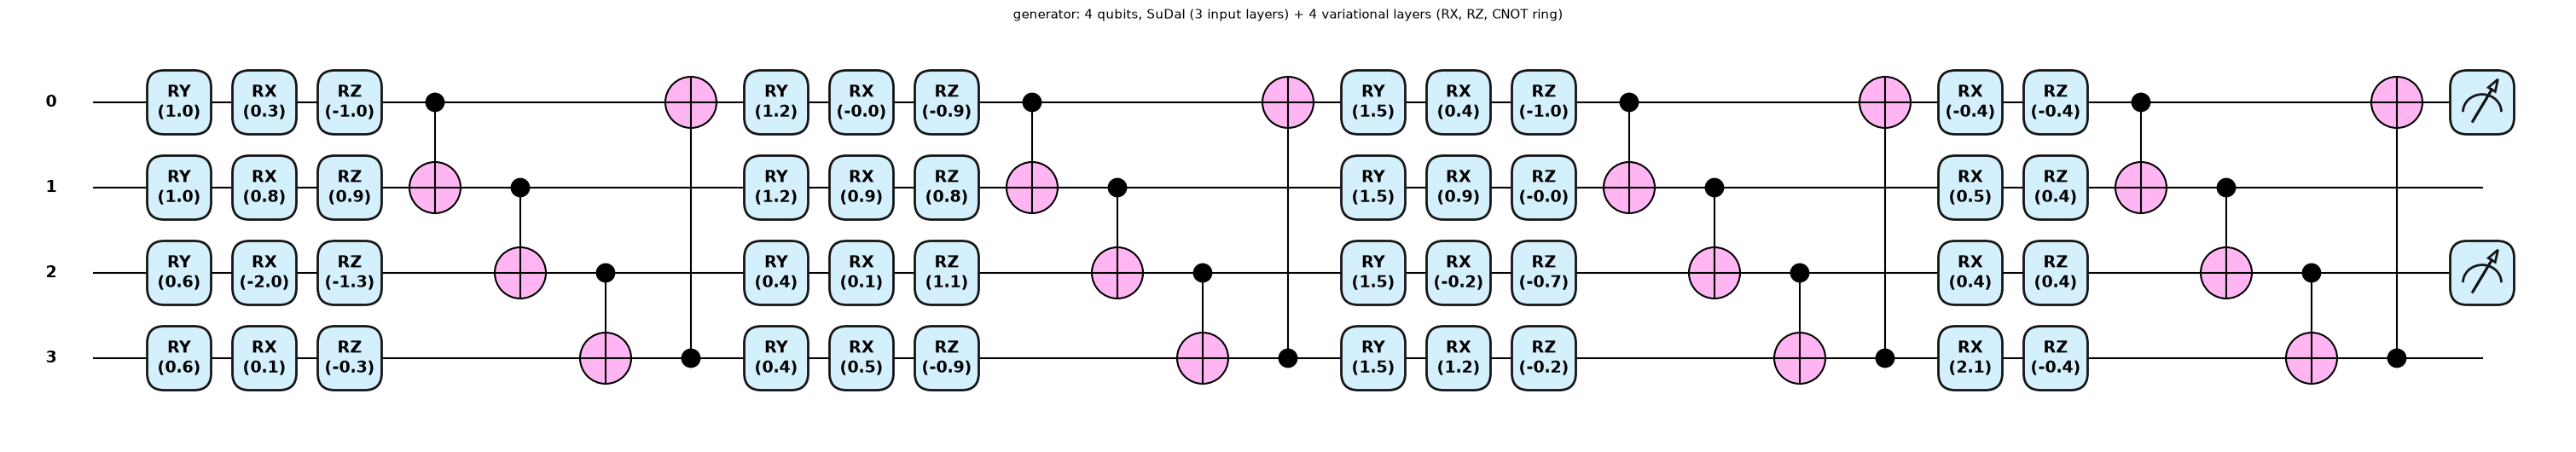

generator {'qubits': 4, 'depth': 27, 'trainable_parameters': 32, 'gates': {'RY': 12, 'RX': 16, 'RZ': 16, 'CNOT': 16}}


   simulator == QNode (max |diff| 6.1e-16); parameter-shift Jacobian == PennyLane's (max |diff| 3.9e-16)


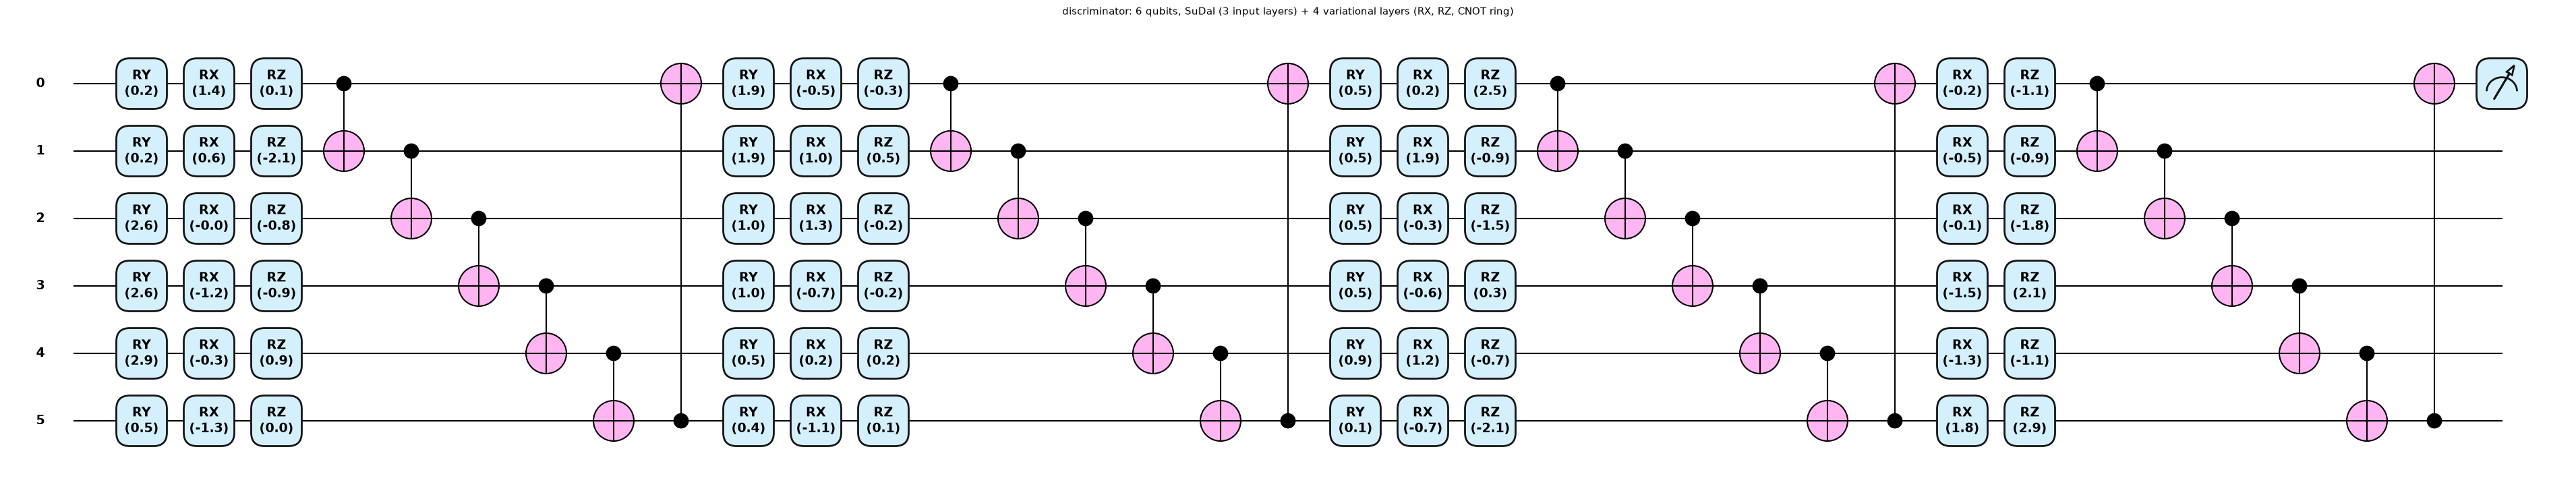

discriminator {'qubits': 6, 'depth': 35, 'trainable_parameters': 48, 'gates': {'RY': 18, 'RX': 24, 'RZ': 24, 'CNOT': 24}}


   simulator == QNode (max |diff| 5.3e-16); parameter-shift Jacobian == PennyLane's (max |diff| 8.0e-16)


generator gradient: parameter-shift chain rule == finite differences (max |diff| 7.8e-12, max |grad| 0.022)
TOTAL quantum parameters: generator 32 + discriminator 48 = 80   (paper: 30 + 50 = 80)


In [13]:
def build_qnode(arch):
    dev = qml.device("default.qubit", wires=arch.n)
    @qml.qnode(dev, diff_method="parameter-shift")
    def circuit(theta, phi):
        th = theta.reshape(arch.L + arch.n_final, arch.n, 2)
        def variational(l):
            for q in range(arch.n):
                qml.RX(th[l, q, 0], wires=q); qml.RZ(th[l, q, 1], wires=q)
            for q in range(arch.n): qml.CNOT(wires=[q, (q + 1) % arch.n])          # ring, last qubit back to the first
        for l in range(arch.L):                                                      # SuDaI: input layer i, then variational layer i
            for v, wires in enumerate(arch.data_wires):
                for w in wires: qml.RY(phi[v, l], wires=w)                          # phi = arccos(x)
            variational(l)
        for l in range(arch.L, arch.L + arch.n_final): variational(l)               # final variational layer V4
        return [qml.expval(qml.PauliZ(w)) for w in arch.out_wires]
    return circuit

qnode_G, qnode_D = build_qnode(G_ARCH), build_qnode(D_ARCH)

def circuit_stats(qnode, arch, theta, phi):
    tape = qml.workflow.construct_batch(qnode, level=0)(theta, phi)[0][0]
    layer = {}                                                                       # greedy layering = circuit depth
    for op in tape.operations:
        d = 1 + max(layer.get(w, 0) for w in op.wires)
        for w in op.wires: layer[w] = d
    n_ops = {}
    for op in tape.operations: n_ops[op.name] = n_ops.get(op.name, 0) + 1
    return dict(qubits=arch.n, depth=max(layer.values()), trainable_parameters=arch.n_var, gates=n_ops)

rs = np.random.default_rng(SEED)
for name, qn, arch in [("generator", qnode_G, G_ARCH), ("discriminator", qnode_D, D_ARCH)]:
    nv = len(arch.data_wires)
    theta0 = rs.normal(0, 1, arch.n_var); phi0 = rs.uniform(0, np.pi, (nv, 3))
    fig, ax = qml.draw_mpl(qn, decimals=1, style="pennylane")(theta0, phi0)
    fig.suptitle(f"{name}: {arch.n} qubits, SuDaI (3 input layers) + {arch.L + arch.n_final} variational layers (RX, RZ, CNOT ring)", y=1.02, fontsize=11)
    plt.show()
    print(name, circuit_stats(qn, arch, theta0, phi0))
    # (i) NumPy simulator == QNode
    TH = rs.normal(0, 1, (4, arch.n_var)); PH = rs.uniform(0, np.pi, (6, nv, 3))
    mine = np.stack([expect(arch, TH[s], PH) for s in range(4)])                     # (4 parameter vectors, 6 inputs, outputs)
    ref = np.array([[[float(z) for z in qn(TH[s], PH[b])] for b in range(6)] for s in range(4)])
    assert np.abs(mine - ref).max() < 1e-10, np.abs(mine - ref).max()
    # (ii) parameter-shift Jacobian == PennyLane's parameter-shift Jacobian (one input)
    base, jac = ps_jacobian(arch, TH[0], PH[:1])
    jac_pl = np.array(qml.jacobian(lambda t: qml.math.stack(qn(t, PH[0])), argnums=0)(qml.numpy.array(TH[0], requires_grad=True))).T   # (P, n_out)
    assert np.abs(jac[:, 0, :] - jac_pl).max() < 1e-9, np.abs(jac[:, 0, :] - jac_pl).max()
    print(f"   simulator == QNode (max |diff| {np.abs(mine - ref).max():.1e}); parameter-shift Jacobian == PennyLane's (max |diff| {np.abs(jac[:, 0, :] - jac_pl).max():.1e})")

# finite-difference check of the full generator gradient (parameter-shift chain rule through the discriminator)
tg_, td_ = rs.normal(0, .3, G_ARCH.n_var), rs.normal(0, .3, D_ARCH.n_var); Wc = rs.uniform(-.8, .8, (6, 3, 2))
LG = lambda t: np.mean((disc_score(td_, Wc, gen_predict(t, Wc)) - 1) ** 2)
fd = np.array([(LG(tg_ + 1e-5 * e) - LG(tg_ - 1e-5 * e)) / 2e-5 for e in np.eye(G_ARCH.n_var)])
an, _ = generator_gradient(tg_, td_, Wc, dclip=1e-12)
assert np.abs(an - fd).max() < 1e-8, np.abs(an - fd).max()
print(f"generator gradient: parameter-shift chain rule == finite differences (max |diff| {np.abs(an - fd).max():.1e}, max |grad| {np.abs(fd).max():.3f})")
print(f"TOTAL quantum parameters: generator {G_ARCH.n_var} + discriminator {D_ARCH.n_var} = {G_ARCH.n_var + D_ARCH.n_var}   (paper: 30 + 50 = 80)")

## 4. The classical conditional GAN baseline

The paper trains a classical GAN "with the same number of parameters as the QGAN" (poor) and then one with 51 generator and 55 discriminator parameters (competitive).
The architecture is not given; we use tiny tanh MLPs with exactly those parameter counts, the same inputs (window of 6 numbers; discriminator: window + next step = 8 numbers),
the same least-squares losses, the same Adam training loop and the same number of steps as the QGAN, written with explicit back-propagation in NumPy:

| model | generator | discriminator | parameters |
|---|---|---|---|
| classical GAN (paper's competitive size) | 6-4-3-2 (51) | 8-4-3-1 (55) | 106 |
| classical GAN, same total as the QGAN | 6-3-2 (29) | 8-5-1 (51) | 80 |

In [14]:
class MLP:
    def __init__(self, sizes, rng, out_act, init=0.5):
        self.W = [rng.normal(0, init / np.sqrt(a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]
        self.out_act = out_act
    def n_params(self): return sum(w.size + b.size for w, b in zip(self.W, self.b))
    def forward(self, x):
        self.acts = [x]
        for i, (w, b) in enumerate(zip(self.W, self.b)):
            z = self.acts[-1] @ w + b
            a = np.tanh(z) if i < len(self.W) - 1 else (np.tanh(z) if self.out_act == "tanh" else 1 / (1 + np.exp(-z)))
            self.acts.append(a)
        return self.acts[-1]
    def backward(self, dout):
        """dout = dL/d(output); returns (grads list, dL/dx)."""
        gW = [None] * len(self.W); gb = [None] * len(self.W)
        a = self.acts[-1]
        d = dout * ((1 - a ** 2) if self.out_act == "tanh" else a * (1 - a))
        for i in reversed(range(len(self.W))):
            gW[i] = self.acts[i].T @ d; gb[i] = d.sum(0)
            dx = d @ self.W[i].T
            if i > 0: d = dx * (1 - self.acts[i] ** 2)
        return gW + gb, dx
    def flat(self): return np.concatenate([p.ravel() for p in self.W + self.b])
    def set_flat(self, v):
        k = 0
        for p in self.W + self.b:
            p[...] = v[k:k + p.size].reshape(p.shape); k += p.size

def cgan_step(g, d, optg, optd, Wn, y):
    B = len(Wn); x = Wn.reshape(B, -1)
    yf = g.forward(x)
    xin = np.concatenate([np.concatenate([x, y], 1), np.concatenate([x, yf], 1)]); tgt = np.concatenate([np.ones(B), np.zeros(B)])[:, None]
    s = d.forward(xin)
    loss_d = np.mean((s - tgt) ** 2)
    grads, _ = d.backward(2 * (s - tgt) / len(s))
    d.set_flat(optd.step(d.flat(), np.concatenate([gr.ravel() for gr in grads])))
    yf = g.forward(x)
    s = d.forward(np.concatenate([x, yf], 1))
    loss_g = np.mean((s - 1) ** 2)
    _, dx = d.backward(2 * (s - 1) / B)
    # dL/d yf = last two columns of dx ; now back-prop through G
    g.forward(x)
    grads, _ = g.backward(dx[:, -2:])
    g.set_flat(optg.step(g.flat(), np.concatenate([gr.ravel() for gr in grads])))
    return loss_g, loss_d

def cgan_score(g, d, Wn, y, wG, wD):
    x = Wn.reshape(len(Wn), -1)
    yh = g.forward(x); mse = ((y - yh) ** 2).mean(1)
    dsc = d.forward(np.concatenate([x, y], 1))[:, 0]
    return wG * mse + wD * (1 - dsc), mse, dsc

## 5. Training

The QGAN is trained on benign windows only. Each step draws a random mini-batch of windows, updates the discriminator and then the generator.
A callback redraws the loss curves every few steps. The classical GANs get the same number of steps and the same batch size.

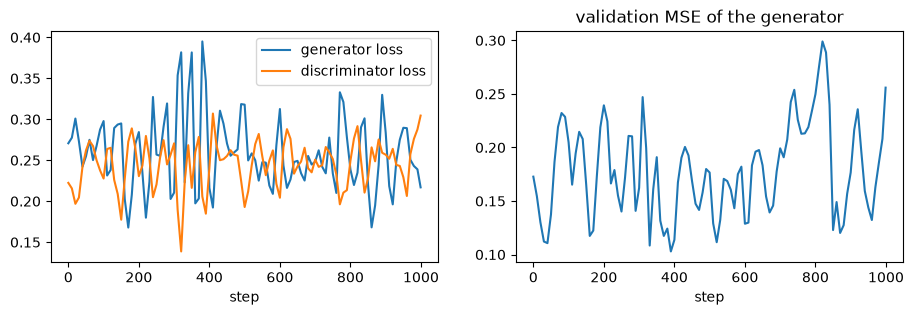

seed 42 step 1000/1000  (459 s)
QGAN seed 42: 1000 steps x batch 16 in 459 s | validation MSE 0.1727 (initial) -> 0.2559 (final)


QGAN seed 43: 1000 steps x batch 16 in 517 s | validation MSE 0.1715 (initial) -> 0.1398 (final)


QGAN seed 44: 1000 steps x batch 16 in 546 s | validation MSE 0.1725 (initial) -> 0.2008 (final)


In [15]:
def train_qgan(seed, steps, batch, lr, W, Y, Wv, Yv, live=False, every=10):
    rng = np.random.default_rng(seed)
    tg = rng.normal(0, INIT_STD, G_ARCH.n_var); td = rng.normal(0, INIT_STD, D_ARCH.n_var)       # CHOICE: near-identity start
    og, od = Adam(G_ARCH.n_var, lr), Adam(D_ARCH.n_var, lr)
    hist = []
    t0 = time.time()
    for it in range(steps):
        idx = rng.choice(len(W), batch, replace=False)
        tg, td, lg, ld = qgan_step(tg, td, W[idx], Y[idx], og, od)
        if it % every == 0 or it == steps - 1:
            vm = float(((gen_predict(tg, Wv[:256]) - Yv[:256]) ** 2).mean())
            hist.append((it, lg, ld, vm))
            if live and (it % (5 * every) == 0 or it == steps - 1):
                clear_output(wait=True); h = np.array(hist)
                fig, ax = plt.subplots(1, 2, figsize=(11, 3))
                ax[0].plot(h[:, 0], h[:, 1], label="generator loss"); ax[0].plot(h[:, 0], h[:, 2], label="discriminator loss"); ax[0].legend(); ax[0].set_xlabel("step")
                ax[1].plot(h[:, 0], h[:, 3]); ax[1].set_title("validation MSE of the generator"); ax[1].set_xlabel("step"); plt.show()
                print(f"seed {seed} step {it + 1}/{steps}  ({time.time() - t0:.0f} s)")
    h = np.array(hist)
    return tg, td, h, time.time() - t0

def last_losses(h, k=25):
    sel = h[-min(k, len(h)):]
    return float(sel[:, 1].mean()), float(sel[:, 2].mean())

qgan_runs = {}
for s in SEEDS_Q:
    tg, td, h, secs = train_qgan(s, QGAN_STEPS, BATCH, LR_QGAN, W_fit, Y_fit, W_val, Y_val, live=(s == SEEDS_Q[0]))
    qgan_runs[s] = dict(tg=tg, td=td, hist=h, secs=secs)
    print(f"QGAN seed {s}: {QGAN_STEPS} steps x batch {BATCH} in {secs:.0f} s | validation MSE {h[0, 3]:.4f} (initial) -> {h[-1, 3]:.4f} (final)")

In [16]:
def train_cgan(seed, arch, steps, batch, lr, W, Y):
    rng = np.random.default_rng(seed)
    g = MLP(arch[0], rng, "tanh"); d = MLP(arch[1], rng, "sigmoid")
    og, od = Adam(g.flat().size, lr), Adam(d.flat().size, lr)
    hist = []
    for it in range(steps):
        idx = rng.choice(len(W), batch, replace=False)
        lg, ld = cgan_step(g, d, og, od, W[idx], Y[idx])
        hist.append((it, lg, ld, 0.0))
    return g, d, np.array(hist)

CG_BIG = ([6, 4, 3, 2], [8, 4, 3, 1]); CG_SAME = ([6, 3, 2], [8, 5, 1])
cgan_runs = {"big": {}, "same": {}}
t0 = time.time()
for s in CGAN_SEEDS:
    for key, arch in (("big", CG_BIG), ("same", CG_SAME)):
        g, d, h = train_cgan(s, arch, QGAN_STEPS, BATCH, LR_CGAN, W_fit, Y_fit)
        cgan_runs[key][s] = dict(g=g, d=d, hist=h)
print("classical GAN parameter counts:", {k: (list(v.values())[0]["g"].n_params(), list(v.values())[0]["d"].n_params()) for k, v in cgan_runs.items()}, f"| {time.time() - t0:.0f} s")

classical GAN parameter counts: {'big': (51, 55), 'same': (29, 51)} | 18 s


## 6. Anomaly scoring and thresholding (Algorithm 1)

For every window the generator predicts the next second; `MSE_t` is the mean squared error between prediction and truth (over the two features) and `D_t` the discriminator's score of the pair
(window, truth). The combined score is `S_t = w_G * MSE_t + w_D * (1 - D_t)` with `w_G = L_D / (L_G + L_D)` and `w_D = L_G / (L_G + L_D)` from the last training losses. The threshold is the
99.99th percentile of the scores of the benign training windows; scores above it are flagged as anomalies. *Generator-only* and *discriminator-only* detection use `w_G = 1` and `w_D = 1` respectively
with their own 99.99th-percentile thresholds. Positive class = attack.

A word on the learning rate and the budget. The paper states 0.001 but not the optimiser, the batch size or the number of epochs, and it seems to have updated after every single window (about 16,000 updates per epoch, each needing two parameter-shift
evaluations per angle on a simulator). That is out of reach here: one training step of this notebook uses a mini-batch of 16 windows and costs about a second on a shared CPU. With only a few hundred to a thousand Adam steps a rate of 0.001 cannot move the
angles far from their initial values, so the configuration cell uses 0.01 (a short exploratory run with 0.03 was visibly more jittery). Only the validation loss on held-out *benign training* windows was looked at for this choice, never the test half.
The adversarial losses of a GAN are noisy, so the last-iterate model is used as is and results are averaged over seeds.

In [17]:
def metrics(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, p), recall=recall_score(y, p, zero_division=0), precision=precision_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def detect(score_tr, score_te, y_te, pct=THRESH_PCT):
    thr = np.percentile(score_tr, pct)
    m = metrics(y_te, (score_te > thr).astype(int))
    m["auroc"] = roc_auc_score(y_te, score_te) if len(np.unique(y_te)) == 2 else float("nan")      # threshold-free ranking quality of the score
    return m, thr

def qgan_scores(run, W, Y):
    lg, ld = last_losses(run["hist"]); wG, wD = ld / (lg + ld), lg / (lg + ld)
    comb, mse, dsc = score_windows(run["tg"], run["td"], W, Y, wG, wD)
    return dict(combined=comb, gen=mse, disc=1 - dsc, mse=mse, wG=wG, wD=wD)

def cgan_scores(run, W, Y):
    lg, ld = last_losses(run["hist"]); wG, wD = ld / (lg + ld), lg / (lg + ld)
    comb, mse, dsc = cgan_score(run["g"], run["d"], W, Y, wG, wD)
    return dict(combined=comb, gen=mse, disc=1 - dsc, mse=mse, wG=wG, wD=wD)

def evaluate_model(score_fn, run, test_sets):
    tr = score_fn(run, W_tr_all, Y_tr_all)
    res = {"train_mse": float(tr["mse"].mean()), "wG": tr["wG"], "wD": tr["wD"]}
    for tname, (W, Y, L) in test_sets.items():
        te = score_fn(run, W, Y)
        for kind in ("disc", "gen", "combined"):
            m, thr = detect(tr[kind], te[kind], L)
            res[(tname, kind)] = m; res[(tname, kind, "thr")] = thr
        res[(tname, "scores")] = te
    res["train_scores"] = tr
    return res

TEST_SETS = {"A": (W_A, Y_A, L_A), "B": (W_B, Y_B, L_B)}
t0 = time.time()
res_q = {s: evaluate_model(qgan_scores, r, TEST_SETS) for s, r in qgan_runs.items()}
res_cb = {s: evaluate_model(cgan_scores, r, TEST_SETS) for s, r in cgan_runs["big"].items()}
res_cs = {s: evaluate_model(cgan_scores, r, TEST_SETS) for s, r in cgan_runs["same"].items()}
print(f"scored all windows in {time.time() - t0:.0f} s")

def table(res, tname, kind, keys=("accuracy", "recall", "precision", "f1", "auroc")):
    arr = np.array([[r[(tname, kind)][k] for k in keys] for r in res.values()])
    return arr.mean(0), arr.std(0)

rows = []
for label, res in [("QGAN (80 params)", res_q), ("classical GAN 51+55 params", res_cb), ("classical GAN 29+51 = 80 params", res_cs)]:
    for tname in ("A", "B"):
        for kind, kn in (("disc", "discriminator only"), ("gen", "generator only"), ("combined", "combined")):
            mu, sd = table(res, tname, kind)
            rows.append([label, f"test {tname}", kn] + [f"{m:.3f} +- {s:.3f}" for m, s in zip(mu, sd)] +
                        [f"{np.mean([r['train_mse'] for r in res.values()]):.4f}"])
tab1 = pd.DataFrame(rows, columns=["model", "test set", "detection", "accuracy", "recall", "precision", "F1", "AUROC", "train MSE"])
display(tab1)
print(f"mean over {len(res_q)} QGAN seed(s) and {len(res_cb)} classical-GAN seeds (+- standard deviation). Test A = the paper's test half; test B = A + the held-out 13:14 burst.")

scored all windows in 171 s


,model,test set,detection,accuracy,recall,precision,F1,AUROC,train MSE
0,QGAN (80 params),test A,discriminator only,0.767 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.352 +- 0.186,0.1130
1,QGAN (80 params),test A,generator only,0.767 +- 0.000,0.002 +- 0.001,0.467 +- 0.368,0.004 +- 0.003,0.750 +- 0.036,0.1130
2,QGAN (80 params),test A,combined,0.767 +- 0.000,0.002 +- 0.002,0.519 +- 0.409,0.004 +- 0.003,0.654 +- 0.062,0.1130
3,QGAN (80 params),test B,discriminator only,0.747 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.370 +- 0.165,0.1130
4,QGAN (80 params),test B,generator only,0.747 +- 0.000,0.002 +- 0.001,0.467 +- 0.368,0.003 +- 0.003,0.721 +- 0.032,0.1130
5,QGAN (80 params),test B,combined,0.747 +- 0.000,0.002 +- 0.001,0.519 +- 0.409,0.003 +- 0.003,0.636 +- 0.054,0.1130
6,classical GAN 51+55 params,test A,discriminator only,0.769 +- 0.004,0.008 +- 0.015,0.399 +- 0.488,0.015 +- 0.029,0.350 +- 0.358,0.2328
7,classical GAN 51+55 params,test A,generator only,0.771 +- 0.007,0.018 +- 0.031,0.599 +- 0.489,0.034 +- 0.057,0.842 +- 0.129,0.2328
8,classical GAN 51+55 params,test A,combined,0.772 +- 0.008,0.020 +- 0.035,0.399 +- 0.489,0.038 +- 0.064,0.842 +- 0.124,0.2328
9,classical GAN 51+55 params,test B,discriminator only,0.748 +- 0.004,0.007 +- 0.014,0.399 +- 0.488,0.013 +- 0.026,0.368 +- 0.312,0.2328


mean over 3 QGAN seed(s) and 5 classical-GAN seeds (+- standard deviation). Test A = the paper's test half; test B = A + the held-out 13:14 burst.


### 6.1 Confusion matrices and the score over time (the analogue of the paper's Fig. 2)

Attack = positive class. The figure shows the QGAN combined anomaly score on the test half against time, the threshold, the ground-truth attack period (shaded) and the
alarms; compare with Fig. 2 of the paper, where yellow marks missed attacks.

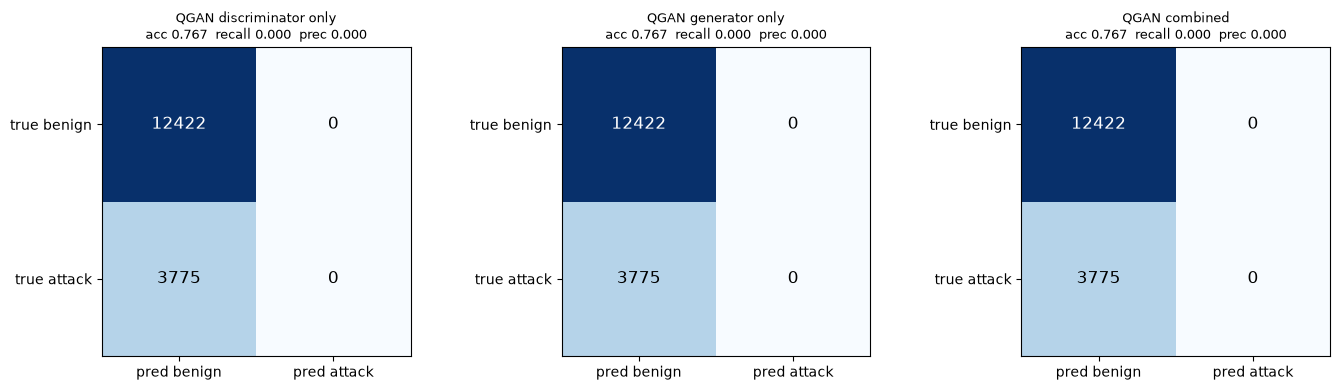

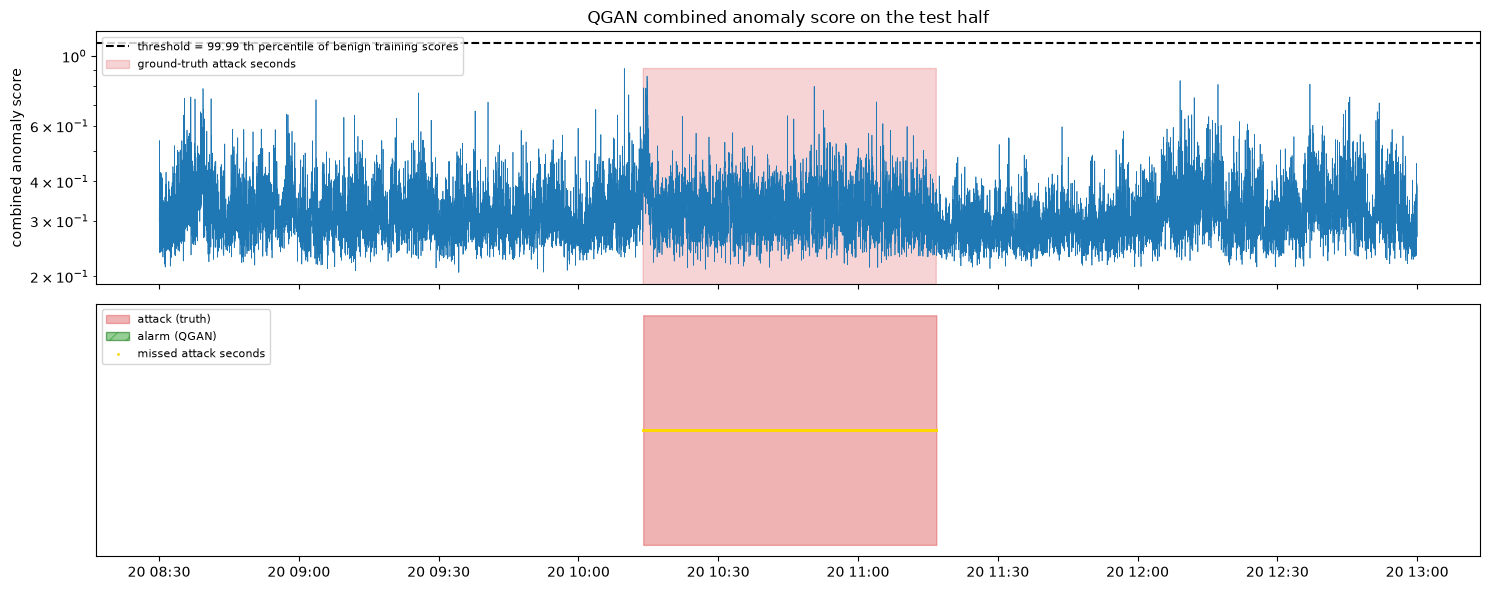

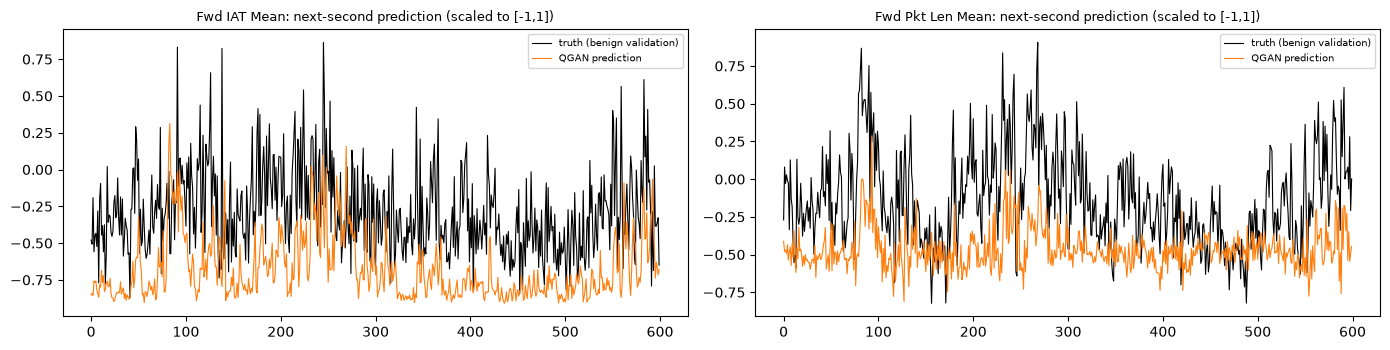

In [18]:
s0 = SEEDS_Q[0]; r0 = res_q[s0]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, kind, ttl in zip(ax, ("disc", "gen", "combined"), ("discriminator only", "generator only", "combined")):
    m = r0[("A", kind)]; cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["pred benign", "pred attack"]); a.set_yticklabels(["true benign", "true attack"])
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", color="k" if v < cm.max() / 2 else "w", fontsize=12)
    a.set_title(f"QGAN {ttl}\nacc {m['accuracy']:.3f}  recall {m['recall']:.3f}  prec {m['precision']:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

sc_te = r0[("A", "scores")]["combined"]; thr = r0[("A", "combined", "thr")]
tt = series.index[J_A]
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
ax[0].plot(tt, sc_te, lw=.5, c="tab:blue"); ax[0].axhline(thr, c="k", ls="--", label=f"threshold = {THRESH_PCT} th percentile of benign training scores")
ax[0].fill_between(tt, 0, sc_te.max(), where=L_A == 1, color="tab:red", alpha=.2, label="ground-truth attack seconds")
ax[0].set_yscale("log"); ax[0].set_ylabel("combined anomaly score"); ax[0].legend(loc="upper left", fontsize=8); ax[0].set_title("QGAN combined anomaly score on the test half")
pred = (sc_te > thr).astype(int)
ax[1].fill_between(tt, 0, 1, where=L_A == 1, step="mid", color="tab:red", alpha=.35, label="attack (truth)")
ax[1].fill_between(tt, 0, 1, where=pred == 1, step="mid", color="tab:green", alpha=.5, label="alarm (QGAN)", hatch="//", edgecolor="darkgreen")
miss = (L_A == 1) & (pred == 0); ax[1].scatter(tt[miss], np.full(miss.sum(), .5), s=1, c="gold", label="missed attack seconds")
ax[1].legend(loc="upper left", fontsize=8); ax[1].set_yticks([]); plt.tight_layout(); plt.show()

# QGAN generator quality: one-step predictions on the validation and the test windows
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
sl = slice(0, 600)
for k, f in enumerate(FEATURES):
    ax[k].plot(Y_val[sl, k] if len(Y_val) >= 600 else Y_val[:, k], c="k", lw=.8, label="truth (benign validation)")
    ax[k].plot(gen_predict(qgan_runs[s0]["tg"], W_val[sl])[:, k], c="tab:orange", lw=.8, label="QGAN prediction")
    ax[k].set_title(f"{f}: next-second prediction (scaled to [-1,1])", fontsize=9); ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 6.2 Ablation: the same generator circuit trained by plain regression

In the GAN the generator is never told the true next value; it only receives the discriminator's verdict. To separate *"the 32-angle SuDaI circuit cannot represent a good one-step predictor"* from *"the adversarial game did not train it
in this budget"*, the same generator circuit is trained here directly on the squared error with the same parameter-shift gradients (no discriminator). This is **not** part of the paper's method; it is a diagnostic. Its error and the
generator-only detection it supports are compared with the adversarially trained generator, with the persistence predictor (`x_t`) and with the mean predictor.

In [19]:
def train_gen_mse(seed, steps, batch, lr, W, Y):
    rng = np.random.default_rng(seed)
    tg = rng.normal(0, INIT_STD, G_ARCH.n_var); opt = Adam(G_ARCH.n_var, lr)
    for it in range(steps):
        idx = rng.choice(len(W), batch, replace=False)
        yh, jg = ps_jacobian(G_ARCH, tg, windows_to_phi_G(W[idx]))                       # parameter-shift Jacobian (P, B, 2)
        grad = np.einsum('bk,pbk->p', 2 * (yh - Y[idx]) / (batch * 2), jg)               # d mean-squared-error / d theta
        tg = opt.step(tg, grad)
    return tg

t0 = time.time()
tg_reg = train_gen_mse(SEED, REG_STEPS, 32, LR_REG, W_fit, Y_fit)
mse_of = lambda yh, y: float(((yh - y) ** 2).mean())
abl = pd.DataFrame([
    dict(generator="predict the training mean", val_MSE=mse_of(Y_fit.mean(0)[None], Y_val)),
    dict(generator="persistence (predict x_t)", val_MSE=mse_of(W_val[:, -1, :], Y_val)),
    dict(generator="QGAN generator, adversarial (this notebook)", val_MSE=mse_of(gen_predict(qgan_runs[s0]["tg"], W_val), Y_val)),
    dict(generator=f"same circuit, regression ({REG_STEPS} steps)", val_MSE=mse_of(gen_predict(tg_reg, W_val), Y_val)),
    dict(generator="classical MLP 6-4-3-2, adversarial", val_MSE=mse_of(cgan_runs["big"][CGAN_SEEDS[0]]["g"].forward(W_val.reshape(len(W_val), -1)), Y_val))])
display(abl.round(4))
sc_reg_tr = ((gen_predict(tg_reg, W_tr_all) - Y_tr_all) ** 2).mean(1); sc_reg_te = ((gen_predict(tg_reg, W_A) - Y_A) ** 2).mean(1)
m_reg, _ = detect(sc_reg_tr, sc_reg_te, L_A)
print(f"generator-only detection with the regression-trained generator (test A): accuracy {m_reg['accuracy']:.3f}, recall {m_reg['recall']:.3f}, precision {m_reg['precision']:.3f}, F1 {m_reg['f1']:.3f}, AUROC {m_reg['auroc']:.3f}  ({time.time() - t0:.0f} s)")

,generator,val_MSE
0,predict the training mean,0.1245
1,persistence (predict x_t),0.0826
2,"QGAN generator, adversarial (this notebook)",0.2162
3,"same circuit, regression (1000 steps)",0.0688
4,"classical MLP 6-4-3-2, adversarial",0.4132


generator-only detection with the regression-trained generator (test A): accuracy 0.768, recall 0.005, precision 1.000, F1 0.009, AUROC 0.935  (40 s)


## 7. The noisy-simulator test ("Fake Vigo")

The paper evaluates the trained QGAN (combined detection) on `Fake Vigo`, a simulated 5-qubit IBM backend. Two obstacles: that backend has 5 qubits but the discriminator has 6 and the CNOT ring
does not fit its T-shaped coupling map, so a literal transpile is impossible. We therefore take the *error rates* of `FakeVigoV2` (average `sx`, `cx` and read-out errors from its calibration
data), and apply them to our circuits in an exact **density-matrix** simulation: depolarising noise after every single-qubit gate (an `RX`/`RY` is two `sx` pulses, `RZ` is virtual) and on both
qubits after every CNOT, plus symmetric read-out error. No SWAP routing and no decoherence are modelled, so this is *optimistic* compared with the real device. The cell asserts that the density-matrix
code agrees with PennyLane's `default.mixed` using the same channels. The trained (noiseless) weights are used; only inference is noisy. Density-matrix simulation of 6 qubits is slow, so the noisy and the
noiseless scores are compared on the *same random subsample* of `N_NOISY` benign training windows (threshold) and `N_NOISY` test-A windows.

In [20]:
def var_rot_unitaries(arch, theta):
    """Single-qubit rotation layers only (no CX): list of (S, dim, dim)."""
    n = arch.n; S = theta.shape[0]
    th = theta.reshape(S, arch.L + arch.n_final, n, 2)
    return [_kron_stack([_mat_rzrx(th[:, l, q, 0], th[:, l, q, 1]) for q in range(n)]) for l in range(arch.L + arch.n_final)]

def _dm_depol(rho, q, n, p):
    """rho -> (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z) on qubit q (PennyLane DepolarizingChannel)."""
    if p <= 0: return rho
    B = rho.shape[0]; lam = 4 * p / 3
    r = rho.reshape(B, 2 ** q, 2, 2 ** (n - q - 1), 2 ** q, 2, 2 ** (n - q - 1))
    tr = r[:, :, 0, :, :, 0, :] + r[:, :, 1, :, :, 1, :]
    new = (1 - lam) * r
    new[:, :, 0, :, :, 0, :] += lam / 2 * tr
    new[:, :, 1, :, :, 1, :] += lam / 2 * tr
    return new.reshape(B, 2 ** n, 2 ** n)

def _cx_perm(n, c, t):
    idx = np.arange(2 ** n)
    return idx ^ (((idx >> (n - 1 - c)) & 1) << (n - 1 - t))

def simulate_noisy(arch, theta, phi, p_1q, p_cx, e_ro):
    """Density-matrix expectation values <Z_w> with depolarising noise after every encoding/rotation gate and after every CX
    (on both qubits), plus symmetric read-out error e_ro. theta: (n_var,), phi: (B, n_vars, L). Returns (B, n_out)."""
    n = arch.n; dim = 2 ** n; B = phi.shape[0]
    R = var_rot_unitaries(arch, theta[None]); E = enc_unitaries(arch, phi)
    rho = np.zeros((B, dim, dim), complex); rho[:, 0, 0] = 1
    def ring(rho):
        for c in range(n):
            t = (c + 1) % n; pm = _cx_perm(n, c, t)
            rho = rho[:, pm][:, :, pm]
            rho = _dm_depol(rho, c, n, p_cx); rho = _dm_depol(rho, t, n, p_cx)
        return rho
    for l in range(arch.L):
        rho = E[l] @ rho @ E[l].conj().transpose(0, 2, 1)
        for q in range(n): rho = _dm_depol(rho, q, n, p_1q)
        rho = R[l] @ rho @ R[l].conj().transpose(0, 2, 1)
        for q in range(n): rho = _dm_depol(rho, q, n, p_1q)
        rho = ring(rho)
    for l in range(arch.L, arch.L + arch.n_final):
        rho = R[l] @ rho @ R[l].conj().transpose(0, 2, 1)
        for q in range(n): rho = _dm_depol(rho, q, n, p_1q)
        rho = ring(rho)
    prob = np.real(np.einsum('bii->bi', rho))
    sign = np.stack([1 - 2 * ((np.arange(dim) >> (n - 1 - w)) & 1) for w in arch.out_wires], axis=1)
    return (prob @ sign) * (1 - 2 * e_ro)

In [21]:
try:
    from qiskit_ibm_runtime.fake_provider import FakeVigoV2
    tgt = FakeVigoV2().target
    err = lambda name: float(np.mean([p.error for p in tgt[name].values() if p is not None and p.error is not None]))
    e_sx, e_cx, e_ro = err("sx"), err("cx"), err("measure"); src = "FakeVigoV2 calibration data"
except Exception as e:
    e_sx, e_cx, e_ro = 5.12e-4, 8.76e-3, 3.34e-2; src = "constants copied from FakeVigoV2 (qiskit-ibm-runtime 0.50.0); import failed: " + repr(e)[:60]
P_1Q = 1.5 * (2 * e_sx)      # CHOICE: depolarising prob. p with average gate infidelity 2p/3 = 2 sx errors (RX/RY = two sx; RZ virtual)
P_CX = 0.75 * e_cx           # CHOICE: independent 1-qubit depolarising on both qubits so that the CNOT error is about e_cx
print(f"error rates from {src}: sx {e_sx:.2e}, cx {e_cx:.2e}, read-out {e_ro:.2e}  ->  p_1q {P_1Q:.2e}, p_cx {P_CX:.2e}")

# equivalence with PennyLane default.mixed (generator circuit, same channels)
def mixed_qnode(arch, p1, pc):
    dev = qml.device("default.mixed", wires=arch.n)
    @qml.qnode(dev)
    def circ(theta, phi):
        th = theta.reshape(arch.L + arch.n_final, arch.n, 2)
        def ring():
            for c in range(arch.n):
                t = (c + 1) % arch.n; qml.CNOT(wires=[c, t]); qml.DepolarizingChannel(pc, wires=c); qml.DepolarizingChannel(pc, wires=t)
        for l in range(arch.L):
            for v, ws in enumerate(arch.data_wires):
                for w in ws: qml.RY(phi[v, l], wires=w)
            for q in range(arch.n): qml.DepolarizingChannel(p1, wires=q)
            for q in range(arch.n): qml.RX(th[l, q, 0], wires=q); qml.RZ(th[l, q, 1], wires=q)
            for q in range(arch.n): qml.DepolarizingChannel(p1, wires=q)
            ring()
        for l in range(arch.L, arch.L + arch.n_final):
            for q in range(arch.n): qml.RX(th[l, q, 0], wires=q); qml.RZ(th[l, q, 1], wires=q)
            for q in range(arch.n): qml.DepolarizingChannel(p1, wires=q)
            ring()
        return [qml.expval(qml.PauliZ(w)) for w in arch.out_wires]
    return circ
rt = np.random.default_rng(1); th_t = rt.normal(0, 1, G_ARCH.n_var); ph_t = rt.uniform(0, np.pi, (3, 2, 3))
ref = np.array([[float(z) * (1 - 2 * e_ro) for z in mixed_qnode(G_ARCH, P_1Q, P_CX)(th_t, ph_t[i])] for i in range(3)])
assert np.abs(simulate_noisy(G_ARCH, th_t, ph_t, P_1Q, P_CX, e_ro) - ref).max() < 1e-9
print("density-matrix simulator == PennyLane default.mixed (generator circuit): OK")

error rates from FakeVigoV2 calibration data: sx 5.12e-04, cx 8.76e-03, read-out 3.34e-02  ->  p_1q 1.54e-03, p_cx 6.57e-03


density-matrix simulator == PennyLane default.mixed (generator circuit): OK


In [22]:
def noisy_scores(run, W, Y, wG, wD, chunk=128):
    comb = np.empty(len(W)); mse = np.empty(len(W)); dsc = np.empty(len(W))
    for i in range(0, len(W), chunk):
        w, y = W[i:i + chunk], Y[i:i + chunk]
        yh = simulate_noisy(G_ARCH, run["tg"], windows_to_phi_G(w), P_1Q, P_CX, e_ro)
        z = simulate_noisy(D_ARCH, run["td"], phi_D(w, y), P_1Q, P_CX, e_ro)[:, 0]
        mse[i:i + chunk] = ((y - yh) ** 2).mean(1); dsc[i:i + chunk] = 0.5 * (1 + z)
    return wG * mse + wD * (1 - dsc), mse, dsc

rn = np.random.default_rng(SEED)
sub_tr = rn.choice(len(W_tr_all), min(N_NOISY, len(W_tr_all)), replace=False)
sub_te = rn.choice(len(W_A), min(N_NOISY, len(W_A)), replace=False)
run0 = qgan_runs[s0]; wG0, wD0 = res_q[s0]["wG"], res_q[s0]["wD"]
t0 = time.time()
sn_tr, mn_tr, _ = noisy_scores(run0, W_tr_all[sub_tr], Y_tr_all[sub_tr], wG0, wD0)
sn_te, mn_te, _ = noisy_scores(run0, W_A[sub_te], Y_A[sub_te], wG0, wD0)
sc_tr0 = res_q[s0]["train_scores"]["combined"][sub_tr]; sc_te0 = res_q[s0][("A", "scores")]["combined"][sub_te]
m_clean, _ = detect(sc_tr0, sc_te0, L_A[sub_te]); m_noisy, _ = detect(sn_tr, sn_te, L_A[sub_te])
print(f"noisy density-matrix evaluation of {len(sub_tr) + len(sub_te)} windows in {time.time() - t0:.0f} s")
noisy_tab = pd.DataFrame([dict(setting="noiseless (same subsample)", **{k: m_clean[k] for k in ("accuracy", "recall", "precision", "f1")}, mse=float(res_q[s0]["train_scores"]["mse"][sub_tr].mean())),
                          dict(setting="noisy (Vigo error rates)", **{k: m_noisy[k] for k in ("accuracy", "recall", "precision", "f1")}, mse=float(mn_tr.mean()))])
display(noisy_tab.round(4))

noisy density-matrix evaluation of 1536 windows in 154 s


,setting,accuracy,recall,precision,f1,mse
0,noiseless (same subsample),0.7617,0.0000,0.0,0.0000,0.1050
1,noisy (Vigo error rates),0.7617,0.0055,0.5,0.0108,0.0586


## 8. The synthetic series (the paper's Figs. 3 and 4)

The paper first checks the generative power on "a synthetic multivariate time series combining a random walk with a modulated sinusoidal wave", with the same number of epochs for both models, and reports
an MSE of 0.015 (QGAN) against 0.078 (classical GAN). Length, periods, noise level and the MSE definition are not given. Here: a random walk and an amplitude- and phase-modulated sine of 700 points,
scaled to [-1, 1], first 70 % for training, last 30 % for the one-step-ahead MSE, same step budget (`SYN_STEPS`) for the QGAN and for the classical GAN with 51 + 55 parameters. This
is a *generated* series by construction (the paper's experiment is synthetic too), it is not a substitute for the network data.

{'QGAN (80 params)': 0.3493, 'classical GAN 51+55': 0.261, 'classical GAN 29+51': 0.1276} | persistence baseline (predict x_t): 0.0131 | 538 s


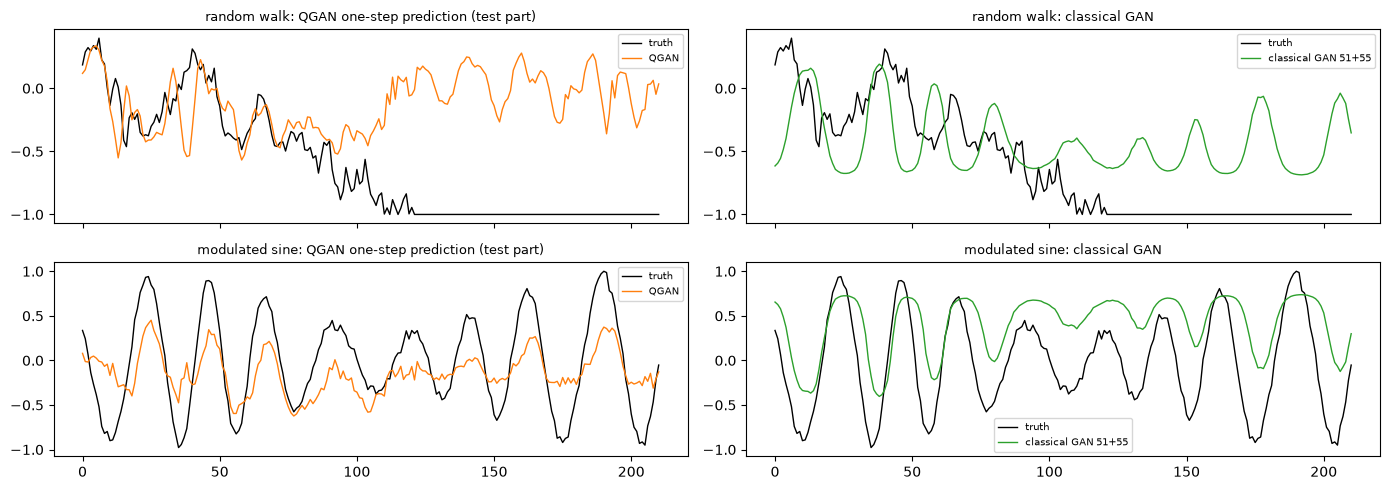

In [23]:
def make_synthetic(T_syn=700, seed=SEED):
    r = np.random.default_rng(seed); t = np.arange(T_syn)
    walk = np.cumsum(r.normal(0, 1, T_syn))
    sine = (1 + 0.5 * np.sin(2 * np.pi * t / 160)) * np.sin(2 * np.pi * t / 24 + 0.8 * np.sin(2 * np.pi * t / 90)) + r.normal(0, 0.05, T_syn)
    X = np.stack([walk, sine], 1)
    ntr = int(0.7 * T_syn)
    lo_, hi_ = X[:ntr].min(0), X[:ntr].max(0)
    return np.clip(2 * (X - lo_) / (hi_ - lo_) - 1, -1, 1), ntr

Xsyn, ntr_syn = make_synthetic()
def win(X, a, b):
    J_ = np.arange(max(a, 3), b); return np.stack([X[J_ - 3], X[J_ - 2], X[J_ - 1]], 1), X[J_]
Ws_tr, Ys_tr = win(Xsyn, 0, ntr_syn); Ws_te, Ys_te = win(Xsyn, ntr_syn, len(Xsyn))
t0 = time.time()
tg_s, td_s, h_s, _ = train_qgan(SEED, SYN_STEPS, min(BATCH, 16), LR_QGAN, Ws_tr, Ys_tr, Ws_te, Ys_te)
gs, ds_, _ = train_cgan(SEED, CG_BIG, SYN_STEPS, min(BATCH, 16), LR_CGAN, Ws_tr, Ys_tr)
gs2, ds2, _ = train_cgan(SEED, CG_SAME, SYN_STEPS, min(BATCH, 16), LR_CGAN, Ws_tr, Ys_tr)
pred_q = gen_predict(tg_s, Ws_te); pred_c = gs.forward(Ws_te.reshape(len(Ws_te), -1)); pred_c2 = gs2.forward(Ws_te.reshape(len(Ws_te), -1))
mse_syn = {k: float(((p - Ys_te) ** 2).mean()) for k, p in [("QGAN (80 params)", pred_q), ("classical GAN 51+55", pred_c), ("classical GAN 29+51", pred_c2)]}
persist = float(((Ws_te[:, -1, :] - Ys_te) ** 2).mean())
print({k: round(v, 4) for k, v in mse_syn.items()}, "| persistence baseline (predict x_t):", round(persist, 4), f"| {time.time() - t0:.0f} s")
fig, ax = plt.subplots(2, 2, figsize=(14, 5), sharex=True)
for k, nm in enumerate(["random walk", "modulated sine"]):
    ax[k, 0].plot(Ys_te[:, k], c="k", lw=1, label="truth"); ax[k, 0].plot(pred_q[:, k], c="tab:orange", lw=1, label="QGAN"); ax[k, 0].set_title(f"{nm}: QGAN one-step prediction (test part)", fontsize=9)
    ax[k, 1].plot(Ys_te[:, k], c="k", lw=1, label="truth"); ax[k, 1].plot(pred_c[:, k], c="tab:green", lw=1, label="classical GAN 51+55"); ax[k, 1].set_title(f"{nm}: classical GAN", fontsize=9)
    ax[k, 0].legend(fontsize=7); ax[k, 1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Other classical detectors on the identical windows

The brief for this repository asks for classical baselines on exactly the same inputs. All of them see the same 6-number windows (three seconds x two scaled features) and the next second:

- **Isolation Forest** and **one-class SVM (RBF)**: unsupervised, trained on the benign training windows only, thresholded with the same 99.99th-percentile rule (input: window + next step, 8 numbers).
- **Random forest** and **SVC (RBF)**: *supervised* references that use attack labels, which the paper's model never sees. Benign-only training data have no attacks, so they are trained on labelled windows of the test half
  with a blocked 2-fold split in time (first half of the timeline vs second half, 4-window gap); this is an optimistic upper reference, not a like-for-like competitor.

In [24]:
X8 = lambda W, Y: np.concatenate([W.reshape(len(W), -1), Y], 1)
Xtr8, XA8 = X8(W_tr_all, Y_tr_all), X8(W_A, Y_A)
rows = []
iso = IsolationForest(n_estimators=200, random_state=SEED).fit(Xtr8)
score_sets = {}
score_sets["Isolation Forest"] = (-iso.score_samples(Xtr8), -iso.score_samples(XA8))
m, _ = detect(*score_sets["Isolation Forest"], L_A); rows.append(("Isolation Forest (benign-only)", m))
sub = rng_global.choice(len(Xtr8), min(4000, len(Xtr8)), replace=False)
oc = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(Xtr8[sub])
score_sets["One-class SVM"] = (-oc.decision_function(Xtr8), -oc.decision_function(XA8))
m, _ = detect(*score_sets["One-class SVM"], L_A); rows.append(("One-class SVM (benign-only)", m))
pe = lambda W, Y: ((W[:, -1, :] - Y) ** 2).mean(1)                              # squared error of the persistence predictor x_t
score_sets["persistence error"] = (pe(W_tr_all, Y_tr_all), pe(W_A, Y_A))
m, _ = detect(*score_sets["persistence error"], L_A); rows.append(("persistence error (predict x_t; benign-only)", m))
score_sets["QGAN generator (regression)"] = (sc_reg_tr, sc_reg_te)
score_sets["QGAN combined (adversarial)"] = (res_q[s0]["train_scores"]["combined"], res_q[s0][("A", "scores")]["combined"])
rows.append(("QGAN generator trained by regression (diagnostic, section 6.2)", m_reg))
mid = len(XA8) // 2
folds = [(np.arange(0, mid - 4), np.arange(mid, len(XA8))), (np.arange(mid + 4, len(XA8)), np.arange(0, mid))]
for nm, mk in [("Random forest (supervised, blocked 2-fold)", lambda: RandomForestClassifier(200, random_state=SEED, n_jobs=1)),
               ("SVC rbf (supervised, blocked 2-fold)", lambda: SVC(kernel="rbf", C=10, gamma="scale"))]:
    pr = np.zeros(len(XA8), int); done = np.zeros(len(XA8), bool)
    for tri, tei in folds:
        if len(np.unique(L_A[tri])) < 2: continue
        clf = mk().fit(XA8[tri][::2], L_A[tri][::2]); pr[tei] = clf.predict(XA8[tei]); done[tei] = True
    m = metrics(L_A[done], pr[done]); rows.append((nm, m))
qm = res_q[s0][("A", "combined")]
rows.append(("QGAN combined (this notebook, seed %d)" % s0, qm))
basetab = pd.DataFrame([dict(model=n, **{k: m.get(k, float("nan")) for k in ("accuracy", "recall", "precision", "f1", "auroc")}) for n, m in rows]); display(basetab.round(3))

# threshold sensitivity (label-free thresholds = percentiles of the benign training scores) and the oracle threshold
from sklearn.metrics import precision_recall_curve
sens = []
for name, (s_tr, s_te) in score_sets.items():
    for pct in (99.99, 99.9, 99.0, 95.0):
        m, _ = detect(s_tr, s_te, L_A, pct); sens.append(dict(score=name, threshold=f"{pct} th percentile (benign train)", **{k: m[k] for k in ("accuracy", "recall", "precision", "f1", "auroc")}))
    pr, rc, th = precision_recall_curve(L_A, s_te); f1s = 2 * pr * rc / np.maximum(pr + rc, 1e-12); k = int(np.argmax(f1s[:-1]))
    pred = (s_te > th[k]).astype(int); m = metrics(L_A, pred)
    sens.append(dict(score=name, threshold="ORACLE best-F1 (uses test labels; upper bound, not a valid result)", accuracy=m["accuracy"], recall=m["recall"], precision=m["precision"], f1=m["f1"], auroc=roc_auc_score(L_A, s_te)))
print("Sensitivity of every benign-only detector to the threshold rule (test A):")
display(pd.DataFrame(sens).round(3))

,model,accuracy,recall,precision,f1,auroc
0,Isolation Forest (benign-only),0.802,0.149,1.000,0.260,0.987
1,One-class SVM (benign-only),0.781,0.059,1.000,0.111,0.960
2,persistence error (predict x_t; benign-only),0.767,0.000,0.000,0.000,0.508
3,QGAN generator trained by regression (diagnost...,0.768,0.005,1.000,0.009,0.935
4,"Random forest (supervised, blocked 2-fold)",0.984,0.951,0.980,0.965,NaN
5,"SVC rbf (supervised, blocked 2-fold)",0.981,0.941,0.975,0.958,NaN
6,"QGAN combined (this notebook, seed 42)",0.767,0.000,0.000,0.000,0.568


Sensitivity of every benign-only detector to the threshold rule (test A):


,score,threshold,accuracy,recall,precision,f1,auroc
0,Isolation Forest,99.99 th percentile (benign train),0.802,0.149,1.000,0.260,0.987
1,Isolation Forest,99.9 th percentile (benign train),0.836,0.295,0.998,0.455,0.987
2,Isolation Forest,99.0 th percentile (benign train),0.921,0.676,0.975,0.799,0.987
3,Isolation Forest,95.0 th percentile (benign train),0.951,0.934,0.865,0.898,0.987
4,Isolation Forest,"ORACLE best-F1 (uses test labels; upper bound,...",0.955,0.899,0.906,0.903,0.987
5,One-class SVM,99.99 th percentile (benign train),0.781,0.059,1.000,0.111,0.960
6,One-class SVM,99.9 th percentile (benign train),0.849,0.358,0.983,0.525,0.960
7,One-class SVM,99.0 th percentile (benign train),0.922,0.725,0.923,0.812,0.960
8,One-class SVM,95.0 th percentile (benign train),0.918,0.872,0.796,0.832,0.960
9,One-class SVM,"ORACLE best-F1 (uses test labels; upper bound,...",0.927,0.843,0.845,0.844,0.960


## 10. Our numbers next to the paper's, with a verdict per claim

Verdict rule: "reproduced" if accuracy is within 2 points (0.02) and the other metrics within 0.02 of the paper's value (recall / precision / F1 on the same 0.02 scale); "not reached" /
"exceeded" with the gap otherwise; "cannot be checked" when the paper gives no way to test the statement. The QGAN rows are means over the seeds trained above; test A is the paper's test half.

In [25]:
def mean_metric(res, tname, kind, key): return float(np.mean([r[(tname, kind)][key] for r in res.values()]))
def verdict(ours, paper, tol=0.02, lower_is_better=False):
    if abs(ours - paper) <= tol: return "reproduced"
    better = ours < paper if lower_is_better else ours > paper
    return f"exceeded (gap {ours - paper:+.4g})" if better else f"not reached (gap {ours - paper:+.4g})"

claims = []
paper_rows = {("QGAN", "disc"): (0.83, 0.35, 0.98, 0.51), ("QGAN", "gen"): (0.26, 1.00, 0.26, 0.41), ("QGAN", "combined"): (0.99, 0.97, 0.99, 0.98),
              ("Classic", "combined"): (0.96, 0.86, 0.99, 0.92)}
for (who, kind), vals in paper_rows.items():
    res = res_q if who == "QGAN" else res_cb
    for key, pv in zip(("accuracy", "recall", "precision", "f1"), vals):
        for tname in ("A", "B"):
            ov = mean_metric(res, tname, kind, key)
            claims.append((f"{who} {kind}-detection {key} (Table I), test {tname}", pv, round(ov, 3), verdict(ov, pv)))
nz = {"accuracy": 0.97, "recall": 0.89, "precision": 0.99, "f1": 0.94}
for key, pv in nz.items(): claims.append((f"Noisy QGAN combined {key} (Table I, subsample)", pv, round(float(noisy_tab.loc[1, key]), 3), verdict(float(noisy_tab.loc[1, key]), pv)))
mq = float(np.mean([r["train_mse"] for r in res_q.values()])); mc = float(np.mean([r["train_mse"] for r in res_cb.values()]))
claims += [("QGAN training MSE (Table I)", 0.0013, round(mq, 4), verdict(mq, 0.0013, 0.002, lower_is_better=True)),
           ("classical GAN (51+55) training MSE (Table I)", 0.0157, round(mc, 4), verdict(mc, 0.0157, 0.002, lower_is_better=True)),
           ("QGAN MSE < classical GAN MSE on the network data", "yes", "yes" if mq < mc else "no", "reproduced" if mq < mc else "not reached"),
           ("noisy QGAN MSE (Table I)", 0.0042, round(float(noisy_tab.loc[1, "mse"]), 4), verdict(float(noisy_tab.loc[1, "mse"]), 0.0042, 0.002, lower_is_better=True)),
           ("synthetic series: QGAN MSE (Fig. 3)", 0.015, round(mse_syn["QGAN (80 params)"], 4), verdict(mse_syn["QGAN (80 params)"], 0.015, 0.01, lower_is_better=True)),
           ("synthetic series: classical GAN MSE (Fig. 4)", 0.078, round(mse_syn["classical GAN 51+55"], 4), verdict(mse_syn["classical GAN 51+55"], 0.078, 0.01, lower_is_better=True)),
           ("synthetic series: QGAN MSE < classical GAN MSE", "yes", "yes" if mse_syn["QGAN (80 params)"] < mse_syn["classical GAN 51+55"] else "no",
            "reproduced" if mse_syn["QGAN (80 params)"] < mse_syn["classical GAN 51+55"] else "not reached"),
           ("total quantum parameters", 80, G_ARCH.n_var + D_ARCH.n_var, "reproduced (split 32 + 48 vs 30 + 50)"),
           ("combined detection beats both single detectors in F1 (test A)", "yes",
            "yes" if mean_metric(res_q, "A", "combined", "f1") > max(mean_metric(res_q, "A", "disc", "f1"), mean_metric(res_q, "A", "gen", "f1")) else "no",
            "reproduced" if mean_metric(res_q, "A", "combined", "f1") > max(mean_metric(res_q, "A", "disc", "f1"), mean_metric(res_q, "A", "gen", "f1")) else "not reached"),
           ("Table II: DNN/CNN/RNN accuracy 98.8-99.8 % (from another paper [38])", "n/a", "n/a", "cannot be checked (different supervised setting, quoted by the paper)"),
           ("robust on real hardware", "n/a", "n/a", "cannot be checked (the paper itself only used a noisy simulator)")]
comp = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
display(comp)
print(comp.verdict.str.split(" ").str[0].value_counts().to_string())

,claim,paper,this notebook,verdict
0,"QGAN disc-detection accuracy (Table I), test A",0.83,0.767,not reached (gap -0.06309)
1,"QGAN disc-detection accuracy (Table I), test B",0.83,0.747,not reached (gap -0.08313)
2,"QGAN disc-detection recall (Table I), test A",0.35,0.0,not reached (gap -0.35)
3,"QGAN disc-detection recall (Table I), test B",0.35,0.0,not reached (gap -0.35)
4,"QGAN disc-detection precision (Table I), test A",0.98,0.0,not reached (gap -0.98)
5,"QGAN disc-detection precision (Table I), test B",0.98,0.0,not reached (gap -0.98)
6,"QGAN disc-detection f1 (Table I), test A",0.51,0.0,not reached (gap -0.51)
7,"QGAN disc-detection f1 (Table I), test B",0.51,0.0,not reached (gap -0.51)
8,"QGAN gen-detection accuracy (Table I), test A",0.26,0.767,exceeded (gap +0.5071)
9,"QGAN gen-detection accuracy (Table I), test B",0.26,0.747,exceeded (gap +0.487)


verdict
not           39
exceeded       4
reproduced     2
cannot         2


## 11. Reading the paper critically

- **What is solid.** The method is clearly specified in its structure: conditional QGAN with SuDaI, angle encoding, parameter-shift training, and an anomaly score that mixes reconstruction error and discriminator output. The
  80-parameter count and the circuit logic are reproducible, and the data are public: the 32,401-entry series is recoverable from the number alone.
- **What is not specified.** Epochs, optimiser, batch size, initialisation, the exact two columns, the label rule for a second, the exact meaning of "two qubits per feature", how the 30 and 50 parameters decompose, what the synthetic
  series looks like and how the noisy simulator was configured. Several of these choices (initialisation, learning rate, number of steps) change the outcome of a 80-parameter adversarial model a lot.
- **The test set and the split.** "Train on the second half, which contains no attacks" does not hold for this file: the second half contains a 15-minute labelled burst at 13:14. The reported numbers (generator-only precision 0.26)
  imply a test prevalence of about 26 %, which matches the first-half attacks plus that burst, not the first half alone (23 %). Our two test sets (A and B) show how much that matters.
- **Threshold rule.** The 99.99th percentile of the benign training scores is practically the *maximum* of ~15,000 scores. With two noisy per-second features that operating point is so conservative that every benign-only detector in this
  notebook (QGAN, classical GANs, Isolation Forest, one-class SVM) flags almost nothing: precision stays high, recall collapses. The threshold-free AUROC tells a different story (the unsupervised Isolation Forest ranks attack windows above
  benign ones very well), so the *information* is in the two features; the headline accuracy/recall of the paper depends on a threshold and a score distribution that this notebook cannot reproduce. The sensitivity table in section 9 shows the effect.
- **GAN training is the weak link.** The generator never sees the true next value, only the discriminator's verdict, and with a noisy series the discriminator stays near 0.5. In our runs the adversarial one-step error of both the QGAN and the classical GANs
  wanders (and is on average worse than simply predicting the training mean), whereas the same 32-angle circuit trained by plain regression (section 6.2) beats the persistence predictor, so the circuit is expressive enough; the paper's very low training MSE (0.0013)
  implies a much smoother series than our per-second means (their exact aggregation is not given).
- **Labels, aggregation and the second burst.** The labels are per flow, not per second, and the paper does not say how a second is labelled. The 13:14-13:29 burst carries the attack label but its per-second features look benign (see the time-series figure),
  so test B adds attack seconds that none of these detectors can separate. Averaging flow-level `Fwd IAT Mean` and `Fwd Pkt Len Mean` over roughly 240 flows per second also yields a noisy series.
- **Fairness of the comparisons.** The classical GAN is a hand-sized MLP of unspecified design; the paper's own first result is that a classical GAN with the QGAN's parameter count performs poorly, and only a 1.3x larger one is competitive.
  Whether the quantum model "needs fewer parameters" depends on how parameters are counted (angles vs weights) and on classical architectures that were not tuned. The simple persistence predictor and unsupervised or supervised
  classical detectors on identical windows (section 9) put the numbers in context.
- **Noise.** A 5-qubit device cannot run a 6-qubit discriminator; the paper's noisy result must have used a noise model without the device's coupling map. Our density-matrix test is likewise optimistic (no routing, no decoherence).
- **No hardware, no variance.** All results are one training run; we report mean +- std over seeds where the budget allowed it.

## 12. Exercises

1. **Different columns.** Replace `Fwd IAT Mean` / `Fwd Pkt Len Mean` by `Fwd IAT Max` and `Fwd Pkt Len Max` (or two columns of your choice from `CAND_COLS`). Which pair separates the attack best, and does the Granger table predict it?
2. **Label rule.** Label a second as an attack only if more than half of its flows are attack flows. How do the test-set prevalence and the metrics change?
3. **Threshold.** Replace the 99.99th percentile by the 99th and 95th. Plot the precision-recall trade-off for the combined score and discuss which operating point a network operator would choose.
4. **Window and injection.** Change `TAU` (and the number of input layers of both circuits) to 2 and 4. Does a longer history help the generator? What happens to the depth printed in the architecture section?
5. **Learning rate and steps.** Rerun the QGAN with `LR_QGAN = 0.001` (the paper's value) and `QGAN_STEPS` ten times larger. Do the validation MSE curves converge, and does the combined detector improve over the persistence predictor `x_t`?